# README
- **Author**: 詹明翰、謝子詮、曾翊涵（共同作者；不推定個別分工）
- **Created At**: 2026-11-26
- **Last Modified At**: 2026-11-26

## What does this file do?
Unit 1.5 幾何／分類驗證。EPSG:3826僅套用面圖層記憶體副本，證據維持B級。固定都市計畫快照不冒充2024–2025各期有效分區；細計-文不作面積分析。不重新執行任何舊Notebook、不處理事故、不做逐里Overlay。
分類表是可審查的研究歸類，非官方完整代碼表。修復與跨類扣除只作診斷試算，尚待學生決定正式規則。糖廍里與其他455里同規則，provisional_match不限制資格；本檔不讀人口或修改里crosswalk。

## What does this file take?
- `data/raw/細計-面.shp` — SHA-256 `67d2ecc469383459e43f2609cf384a4129e09b27c590cbbb82dfa750eba758ee`
- `data/raw/細計-面.shx` — SHA-256 `277e5f623c5c81865aa7288fac979a279b340899a4b3bc4335638f797fc5fd69`
- `data/raw/細計-面.dbf` — SHA-256 `29b0484feef66c6c8417821ada8a28ed1edc0efcdffb492476fe7ada8739e1d4`
- `data/raw/細計-文.shp` — SHA-256 `fa1767fc78c69b7683ec53e0fab8937bac6c33868bedee3c3dcc2ed38dcab731`
- `data/raw/細計-文.shx` — SHA-256 `32d642964d494f49d08830f9c12857f9f4995b56eebf09ef2be994034b864760`
- `data/raw/細計-文.dbf` — SHA-256 `eba92881fc11e574f24024380c946d73cf213e86040663c4070d15b1d552a7be`
- `data/raw/G97_A_CAVLGE_P.shp` — SHA-256 `f7fb4813a2283198ca564f5686823c454c5fd832d2f6981a2ee88a94719be3cc`
- `data/raw/G97_A_CAVLGE_P.shx` — SHA-256 `ab7bc5e63229f676d3580b68e98db59b91a2d327c74ca23b0000ca1c568d414e`
- `data/raw/G97_A_CAVLGE_P.dbf` — SHA-256 `2f43f92e84279a45b2512cf453e9b72f706d1ad1402665c946b1a354f75d8577`
- `data/raw/G97_A_CAVLGE_P.prj` — SHA-256 `8dac7d82ea889063f9eaa7df408fcaeb7307d32831ea973b6534d0139a4523c5`
- `data/raw/G97_A_CAVLGE_P.cpg` — SHA-256 `3ad3031f5503a4404af825262ee8232cc04d4ea6683d42c5dd0a2f2a27ac9824`
- `data/raw/unit14_urban_planning_evidence.zip` — SHA-256 `695e15f7230c076b2b827f72b4337273ff795f6fc7e9c52680641c972dd72730`
- `data/raw/unit15_zoning_classification_evidence.zip` — SHA-256 `82effe1535fc7577d73accf81ee0663daa78944a11517b9e50c7bc2e197ba9b9`

原資料文件：[都市計畫](../raw/taipei_urban_planning_raw_documentation.ipynb)、[里界](../raw/taipei_village_boundaries_raw_documentation.ipynb)、[Unit 1.4證據](../raw/unit14_urban_planning_evidence_documentation.ipynb)、[新增分類證據](../raw/unit15_zoning_classification_evidence_documentation.ipynb)。點檔僅驗證hash，不讀取分析。

## What does this file output?
- [urban_zoning_crosswalk.csv](../processed/urban_zoning_crosswalk.csv)：role=crosswalk；296個五欄複合鍵、12欄，原始紀錄計數總和15518。唯一新衍生資料表；分類含待確認狀態，非逐里B2。
- [processed documentation](../processed/urban_zoning_crosswalk_documentation.ipynb)。輸出寫後重讀、檢查鍵／schema／計數／類別，實際hash由下方輸出並登記文件與PROJECT。
- 診斷表／圖保存在本Notebook；暫存摘要與PNG位於ignored `data/temp/unit15_validation/`，非正式資料交接；不輸出修復後GIS或逐里比例。


In [1]:
from pathlib import Path
from datetime import datetime,timezone
import hashlib,json,io,zipfile,sys,os,platform
import numpy as np
import pandas as pd
from IPython.display import display,Markdown
def root():
    for p in (Path.cwd().resolve(),*Path.cwd().resolve().parents):
        if (p/'AGENTS.md').is_file() and (p/'templates').is_dir():return p
    raise FileNotFoundError('Open within the student project')
ROOT=root();TEMP=ROOT/'data/temp/unit15_validation';TEMP.mkdir(parents=True,exist_ok=True)
assert Path(sys.executable).resolve()==(ROOT/'.venv/Scripts/python.exe').resolve()
os.environ['PROJ_NETWORK']='OFF'
def sha(p):return hashlib.sha256(p.read_bytes()).hexdigest()
def verify(bindings):
    rows=[]
    for relative,h in bindings.items():
        p=(ROOT/relative).resolve()
        assert p.is_relative_to((ROOT/'data').resolve()) and p.is_file(),relative
        assert sha(p)==h,'Input version changed: '+relative
        rows.append(dict(path=relative,bytes=p.stat().st_size,sha256=h))
    return pd.DataFrame(rows)
def show(title,frame,block=18):
    display(Markdown('**'+title+'**'))
    if len(frame)==0:display(Markdown('無符合紀錄。'))
    for start in range(0,len(frame),block):display(frame.iloc[start:start+block])
pd.set_option('display.max_colwidth',110)
pd.set_option('display.max_columns',22)
print({'python':platform.python_version(),'venv':True,'validation_date':'2026-11-26','network_in_kernel':False})


{'python': '3.12.2', 'venv': True, 'validation_date': '2026-11-26', 'network_in_kernel': False}


In [2]:
EXPECTED_SHA256={'data/raw/細計-面.shp': '67d2ecc469383459e43f2609cf384a4129e09b27c590cbbb82dfa750eba758ee', 'data/raw/細計-面.shx': '277e5f623c5c81865aa7288fac979a279b340899a4b3bc4335638f797fc5fd69', 'data/raw/細計-面.dbf': '29b0484feef66c6c8417821ada8a28ed1edc0efcdffb492476fe7ada8739e1d4', 'data/raw/細計-文.shp': 'fa1767fc78c69b7683ec53e0fab8937bac6c33868bedee3c3dcc2ed38dcab731', 'data/raw/細計-文.shx': '32d642964d494f49d08830f9c12857f9f4995b56eebf09ef2be994034b864760', 'data/raw/細計-文.dbf': 'eba92881fc11e574f24024380c946d73cf213e86040663c4070d15b1d552a7be', 'data/raw/G97_A_CAVLGE_P.shp': 'f7fb4813a2283198ca564f5686823c454c5fd832d2f6981a2ee88a94719be3cc', 'data/raw/G97_A_CAVLGE_P.shx': 'ab7bc5e63229f676d3580b68e98db59b91a2d327c74ca23b0000ca1c568d414e', 'data/raw/G97_A_CAVLGE_P.dbf': '2f43f92e84279a45b2512cf453e9b72f706d1ad1402665c946b1a354f75d8577', 'data/raw/G97_A_CAVLGE_P.prj': '8dac7d82ea889063f9eaa7df408fcaeb7307d32831ea973b6534d0139a4523c5', 'data/raw/G97_A_CAVLGE_P.cpg': '3ad3031f5503a4404af825262ee8232cc04d4ea6683d42c5dd0a2f2a27ac9824', 'data/raw/unit14_urban_planning_evidence.zip': '695e15f7230c076b2b827f72b4337273ff795f6fc7e9c52680641c972dd72730', 'data/raw/unit15_zoning_classification_evidence.zip': '82effe1535fc7577d73accf81ee0663daa78944a11517b9e50c7bc2e197ba9b9'}
display(verify(EXPECTED_SHA256))


,path,bytes,sha256
0,data/raw/細計-面.shp,7556848,67d2ecc469383459e43f2609cf384a4129e09b27c590cbbb82dfa750eba758ee
1,data/raw/細計-面.shx,124244,277e5f623c5c81865aa7288fac979a279b340899a4b3bc4335638f797fc5fd69
2,data/raw/細計-面.dbf,13982136,29b0484feef66c6c8417821ada8a28ed1edc0efcdffb492476fe7ada8739e1d4
3,data/raw/細計-文.shp,184,fa1767fc78c69b7683ec53e0fab8937bac6c33868bedee3c3dcc2ed38dcab731
4,data/raw/細計-文.shx,124,32d642964d494f49d08830f9c12857f9f4995b56eebf09ef2be994034b864760
5,data/raw/細計-文.dbf,3121,eba92881fc11e574f24024380c946d73cf213e86040663c4070d15b1d552a7be
6,data/raw/G97_A_CAVLGE_P.shp,765784,f7fb4813a2283198ca564f5686823c454c5fd832d2f6981a2ee88a94719be3cc
7,data/raw/G97_A_CAVLGE_P.shx,3748,ab7bc5e63229f676d3580b68e98db59b91a2d327c74ca23b0000ca1c568d414e
8,data/raw/G97_A_CAVLGE_P.dbf,272706,2f43f92e84279a45b2512cf453e9b72f706d1ad1402665c946b1a354f75d8577
9,data/raw/G97_A_CAVLGE_P.prj,399,8dac7d82ea889063f9eaa7df408fcaeb7307d32831ea973b6534d0139a4523c5


## 1. Working CRS and source
承接學生通過的Unit 1.4：面層工作EPSG:3826，B級strongly supported，不補PRJ、不重開datum推定。官方細計來源與本機六檔同bytes之既有證據見Unit 1.4。固定里界僅取全市聯集作覆蓋分母，不變更456個原幾何。所有面積單位為工作投影m²，換算km²除以10⁶；不是法定測量面積。


In [3]:
import geopandas as gpd
import shapely as s
import matplotlib.pyplot as plt
from matplotlib import font_manager
font=Path('C:/Windows/Fonts/msjh.ttc')
if font.is_file():font_manager.fontManager.addfont(str(font));plt.rcParams['font.family']=[font_manager.FontProperties(fname=str(font)).get_name(),'DejaVu Sans']
plt.rcParams['axes.unicode_minus']=False
def finish(fig,name):
    fig.tight_layout();fig.savefig(TEMP/(name+'.png'),dpi=150,bbox_inches='tight');plt.show();plt.close(fig)
raw=gpd.read_file(ROOT/'data/raw/細計-面.shp',engine='pyogrio',encoding='cp950')
assert raw.crs is None and len(raw)==15518
assert raw.geom_type.value_counts().to_dict()=={'Polygon':15508,'MultiPolygon':10}
work=raw.copy().set_crs(epsg=3826)
villages=gpd.read_file(ROOT/'data/raw/G97_A_CAVLGE_P.shp',engine='pyogrio',encoding='utf-8')
assert len(villages)==456 and villages.crs.to_epsg()==3826 and villages.geometry.is_valid.all()
city=s.union_all(villages.geometry.array)
assert city.is_valid and not city.is_empty
print({'records':len(raw),'layers':raw['圖層'].nunique(),'codes':raw['分區代碼'].nunique(),'original_crs':str(raw.crs),'working_crs':'EPSG:3826 / B級','city_union_km2':city.area/1e6,'shapely':s.__version__,'GEOS':s.geos_version_string})


{'records': 15518, 'layers': 97, 'codes': 260, 'original_crs': 'None', 'working_crs': 'EPSG:3826 / B級', 'city_union_km2': 268.5500826693036, 'shapely': '2.2.0', 'GEOS': '3.14.1'}


## 2. Explicit zoning review ledger and official evidence
2023-08-04歷史版及2025-07-09現行自治條例第3條支持住宅、商業、工業、文教、農業、保護、河川、保存及特定專用等原始語義；都發局名詞解釋支持公共設施內交通、教育、公園綠地等大類。這些來源沒有把全部260個本機代碼逐一認證，也沒有提供跨類面重疊的優先序。Unit 1.4 renderer 221值僅參考，不當完整碼表。

以下為逐代碼、名稱、描述及簡稱檢閱後固定的296組白名單；新版本／新鍵必須停止。非全域關鍵字分類。普通住宅(特)、商業(特)仍可按明示母類做寬類研究映射，但不是個案法定用途認證；真正特專／混合／聯開另留mixed_special_use。B展會指定及IF產業服務的寬類歸入需學生審查，保守排除亦可。


In [4]:
with zipfile.ZipFile(ROOT/'data/raw/unit15_zoning_classification_evidence.zip') as z:
    manifest=json.loads(z.read('source_manifest.json'))
    for row in manifest:assert hashlib.sha256(z.read(row['file'])).hexdigest()==row['sha256']
display(pd.DataFrame(manifest)[['file','url','content_type','bytes','sha256']])
import pymupdf
from bs4 import BeautifulSoup
with zipfile.ZipFile(ROOT/'data/raw/unit15_zoning_classification_evidence.zip') as z:
    pdf=pymupdf.open(stream=z.read('taipei_zoning_regulation_20230804.html'),filetype='pdf')
    historical=''.join(p.get_text() for p in pdf)
    current=BeautifulSoup(z.read('taipei_zoning_regulation_current.html'),'html.parser').get_text(' ',strip=True)
    terms=BeautifulSoup(z.read('udd_official_terms.html'),'html.parser').get_text(' ',strip=True)
assert '112 年 08 月 04 日' in historical
for word in ['住宅區','商業區','工業區','文教區','保護區','特定專用區']:assert word in historical and word in current
assert '公共設施用地' in terms and '特定專用區' in terms
print('原始回應逐件hash通過；歷史PDF74頁、版本112-08-04已核對。歷史檔封裝名稱雖為.html，實為application/pdf，依magic與Content-Type解析，不改原始bytes。僅引用分類語義，不認證2024–2025各地塊生效狀態。')


,file,url,content_type,bytes,sha256
0,taipei_zoning_regulation_current.html,https://laws.gov.taipei/Law/LawSearch/LawArticleContent/FL003962,text/html; charset=utf-8,229418,7d5a52dfdd7d16895813561fc31e6ba33b20618fb257f0e89e87e6aae33bb5f8
1,taipei_zoning_regulation_20230804.html,https://www.laws.taipei.gov.tw/law/LawSearch/LawExport/FL003962?date=20230804&type=0,application/pdf,263760,7cc297bb8fec4768458f835628dacdc4637a481437bbb38bf9c2bcb409b1861f
2,udd_official_terms.html,https://udd.gov.taipei/PublicParticipation/noun-explanation,text/html; charset=utf-8,19105,e4ae8fd354cbd9fdf072cd817305f3ff475547501d06ce91c574bda94609bceb


原始回應逐件hash通過；歷史PDF74頁、版本112-08-04已核對。歷史檔封裝名稱雖為.html，實為application/pdf，依magic與Content-Type解析，不改原始bytes。僅引用分類語義，不認證2024–2025各地塊生效狀態。


In [5]:
REVIEWED=[{'圖層': '1', '分區代碼': 'R1', '使用分區': '第一種住宅區', '分區說明': '', '分區簡稱': '住1', 'n': 107, 'research_zoning_category': 'residential'}, {'圖層': '1', '分區代碼': 'R1A', '使用分區': '第一種住宅區(特)', '分區說明': '', '分區簡稱': '住1(特)', 'n': 5, 'research_zoning_category': 'residential'}, {'圖層': '10', '分區代碼': 'R', '使用分區': '住宅區', '分區說明': '', '分區簡稱': '住', 'n': 156, 'research_zoning_category': 'residential'}, {'圖層': '10', '分區代碼': 'R5', '使用分區': '特定休閒旅館住宅專用區', '分區說明': '', '分區簡稱': '休閒', 'n': 25, 'research_zoning_category': 'mixed_special_use'}, {'圖層': '10', '分區代碼': 'RA', '使用分區': '第壹類住宅用地', '分區說明': '', '分區簡稱': '住1類', 'n': 3, 'research_zoning_category': 'residential'}, {'圖層': '10', '分區代碼': 'RAA', '使用分區': '住宅區(特)', '分區說明': '', '分區簡稱': '住(特)', 'n': 8, 'research_zoning_category': 'residential'}, {'圖層': '10', '分區代碼': 'RB', '使用分區': '第貳類住宅用地', '分區說明': '', '分區簡稱': '住2類', 'n': 14, 'research_zoning_category': 'residential'}, {'圖層': '10', '分區代碼': 'RC', '使用分區': '第參類住宅用地', '分區說明': '', '分區簡稱': '住3類', 'n': 18, 'research_zoning_category': 'residential'}, {'圖層': '10', '分區代碼': 'RD', '使用分區': '駐華使領館辦公暨住宅專用區', '分區說明': '', '分區簡稱': '使館住專', 'n': 1, 'research_zoning_category': 'mixed_special_use'}, {'圖層': '10', '分區代碼': 'REA', '使用分區': '特定專用區(三)(供住宅使用)', '分區說明': '', '分區簡稱': '特(三)', 'n': 19, 'research_zoning_category': 'mixed_special_use'}, {'圖層': '10', '分區代碼': 'REB', '使用分區': '特定專用區(四)(供河濱住宅使用)', '分區說明': '', '分區簡稱': '特(四)', 'n': 10, 'research_zoning_category': 'mixed_special_use'}, {'圖層': '10', '分區代碼': 'REC', '使用分區': '特定專用區(一)', '分區說明': '', '分區簡稱': '特(一)', 'n': 20, 'research_zoning_category': 'mixed_special_use'}, {'圖層': '10', '分區代碼': 'REC', '使用分區': '特定專用區(一)', '分區說明': '(F2)', '分區簡稱': '特(一)', 'n': 1, 'research_zoning_category': 'mixed_special_use'}, {'圖層': '10', '分區代碼': 'REC', '使用分區': '特定專用區(一)', '分區說明': '(F5)', '分區簡稱': '特(一)', 'n': 1, 'research_zoning_category': 'mixed_special_use'}, {'圖層': '10', '分區代碼': 'REC', '使用分區': '特定專用區(一)', '分區說明': 'D1', '分區簡稱': '特(一)', 'n': 1, 'research_zoning_category': 'mixed_special_use'}, {'圖層': '10', '分區代碼': 'REC', '使用分區': '特定專用區(一)', '分區說明': 'F1', '分區簡稱': '特(一)', 'n': 1, 'research_zoning_category': 'mixed_special_use'}, {'圖層': '10', '分區代碼': 'REC', '使用分區': '特定專用區(一)', '分區說明': 'F4', '分區簡稱': '特(一)', 'n': 1, 'research_zoning_category': 'mixed_special_use'}, {'圖層': '10', '分區代碼': 'RED', '使用分區': '特定專用區(二)', '分區說明': '', '分區簡稱': '特(二)', 'n': 14, 'research_zoning_category': 'mixed_special_use'}, {'圖層': '10', '分區代碼': 'RED', '使用分區': '特定專用區(二)', '分區說明': 'A1', '分區簡稱': '特(二)', 'n': 1, 'research_zoning_category': 'mixed_special_use'}, {'圖層': '10', '分區代碼': 'RF', '使用分區': '特定住宅區', '分區說明': '', '分區簡稱': '特住', 'n': 7, 'research_zoning_category': 'residential'}, {'圖層': '10', '分區代碼': 'RF', '使用分區': '特定住宅區', '分區說明': '(一)', '分區簡稱': '特住', 'n': 18, 'research_zoning_category': 'residential'}, {'圖層': '10', '分區代碼': 'RF', '使用分區': '特定住宅區', '分區說明': '(二)', '分區簡稱': '特住', 'n': 20, 'research_zoning_category': 'residential'}, {'圖層': '10', '分區代碼': 'RG', '使用分區': '專案住宅區', '分區說明': '', '分區簡稱': '專住', 'n': 2, 'research_zoning_category': 'residential'}, {'圖層': '10', '分區代碼': 'RH', '使用分區': '市民住宅區', '分區說明': '', '分區簡稱': '市住', 'n': 6, 'research_zoning_category': 'residential'}, {'圖層': '10', '分區代碼': 'RR', '使用分區': '住宅用地', '分區說明': '', '分區簡稱': '住用', 'n': 101, 'research_zoning_category': 'residential'}, {'圖層': '11', '分區代碼': 'B', '使用分區': '商業區', '分區說明': '', '分區簡稱': '商', 'n': 19, 'research_zoning_category': 'commercial'}, {'圖層': '11', '分區代碼': 'B', '使用分區': '商業區', '分區說明': '(供商務設施使用)', '分區簡稱': '商', 'n': 1, 'research_zoning_category': 'commercial'}, {'圖層': '11', '分區代碼': 'B', '使用分區': '商業區', '分區說明': '(供第二代展會中心使用)', '分區簡稱': '商', 'n': 1, 'research_zoning_category': 'commercial'}, {'圖層': '11', '分區代碼': 'B', '使用分區': '商業區', '分區說明': '供一般商業使用', '分區簡稱': '商', 'n': 9, 'research_zoning_category': 'commercial'}, {'圖層': '11', '分區代碼': 'B', '使用分區': '商業區', '分區說明': '供商業購物中心使用', '分區簡稱': '商', 'n': 2, 'research_zoning_category': 'commercial'}, {'圖層': '11', '分區代碼': 'B', '使用分區': '商業區', '分區說明': '供觀光旅館使用', '分區簡稱': '商', 'n': 1, 'research_zoning_category': 'commercial'}, {'圖層': '112', '分區代碼': 'PUB', '使用分區': '電力設施用地', '分區說明': '', '分區簡稱': '電力', 'n': 65, 'research_zoning_category': 'other_public_facilities'}, {'圖層': '118', '分區代碼': 'PUC1', '使用分區': '電信專用區', '分區說明': '', '分區簡稱': '電信專用', 'n': 3, 'research_zoning_category': 'other_public_facilities'}, {'圖層': '12', '分區代碼': 'B1', '使用分區': '第一種商業區', '分區說明': '', '分區簡稱': '商1', 'n': 118, 'research_zoning_category': 'commercial'}, {'圖層': '13', '分區代碼': 'B1A', '使用分區': '第一種商業區(特)', '分區說明': '', '分區簡稱': '商一特', 'n': 114, 'research_zoning_category': 'commercial'}, {'圖層': '14', '分區代碼': 'B2', '使用分區': '第二種商業區', '分區說明': '', '分區簡稱': '商2', 'n': 80, 'research_zoning_category': 'commercial'}, {'圖層': '14', '分區代碼': 'IGA', '使用分區': '科技工業區(A區)', '分區說明': '', '分區簡稱': '科工A', 'n': 45, 'research_zoning_category': 'industrial'}, {'圖層': '144', '分區代碼': 'PTE4', '使用分區': '調度站用地', '分區說明': '', '分區簡稱': '調', 'n': 6, 'research_zoning_category': 'transportation'}, {'圖層': '145', '分區代碼': 'PTE5', '使用分區': '公車調度站用地', '分區說明': '', '分區簡稱': '公調', 'n': 5, 'research_zoning_category': 'transportation'}, {'圖層': '148', '分區代碼': 'PTG3', '使用分區': '捷運系統用地', '分區說明': '', '分區簡稱': '捷', 'n': 10, 'research_zoning_category': 'transportation'}, {'圖層': '15', '分區代碼': 'B2A', '使用分區': '第二種商業區(特)', '分區說明': '', '分區簡稱': '商二特', 'n': 111, 'research_zoning_category': 'commercial'}, {'圖層': '15', '分區代碼': 'IGB', '使用分區': '科技工業區(B區)', '分區說明': '', '分區簡稱': '科工B', 'n': 10, 'research_zoning_category': 'industrial'}, {'圖層': '16', '分區代碼': 'B3', '使用分區': '第三種商業區', '分區說明': '', '分區簡稱': '商3', 'n': 439, 'research_zoning_category': 'commercial'}, {'圖層': '16', '分區代碼': 'IGC', '使用分區': '科技工業區(C區)', '分區說明': '', '分區簡稱': '科工C', 'n': 26, 'research_zoning_category': 'industrial'}, {'圖層': '17', '分區代碼': 'B3A', '使用分區': '第三種商業區(特)', '分區說明': '', '分區簡稱': '商三特', 'n': 1425, 'research_zoning_category': 'commercial'}, {'圖層': '17', '分區代碼': 'B3B', '使用分區': '第三種商業區(特)(遷)', '分區說明': '', '分區簡稱': '商三特(遷)', 'n': 21, 'research_zoning_category': 'commercial'}, {'圖層': '17', '分區代碼': 'IGD', '使用分區': '科技工業區(D區)', '分區說明': '', '分區簡稱': '科工D', 'n': 10, 'research_zoning_category': 'industrial'}, {'圖層': '18', '分區代碼': 'B4', '使用分區': '第四種商業區', '分區說明': '', '分區簡稱': '商4', 'n': 191, 'research_zoning_category': 'commercial'}, {'圖層': '187', '分區代碼': 'CHA1', '使用分區': '文教區(供私立薇閣中小學使用)', '分區說明': '', '分區簡稱': '文教', 'n': 1, 'research_zoning_category': 'educational'}, {'圖層': '188', '分區代碼': 'CHB1', '使用分區': '文教區(特)(供私立薇閣中小學使用)', '分區說明': '', '分區簡稱': '文教(特)', 'n': 1, 'research_zoning_category': 'educational'}, {'圖層': '189', '分區代碼': 'CIA1', '使用分區': '文教區(供幼華高級中學使用)', '分區說明': '', '分區簡稱': '文教', 'n': 1, 'research_zoning_category': 'educational'}, {'圖層': '19', '分區代碼': 'B4A', '使用分區': '第四種商業區(特)', '分區說明': '', '分區簡稱': '商四特', 'n': 259, 'research_zoning_category': 'commercial'}, {'圖層': '190', '分區代碼': 'CIA2', '使用分區': '文教區(供奎山實驗高級中等學校使用)', '分區說明': '', '分區簡稱': '文教', 'n': 1, 'research_zoning_category': 'educational'}, {'圖層': '191', '分區代碼': 'CIA4', '使用分區': '文教區(供私立東山高中使用)(一)', '分區說明': '', '分區簡稱': '文教', 'n': 1, 'research_zoning_category': 'educational'}, {'圖層': '191', '分區代碼': 'CIA5', '使用分區': '文教區(供私立東山高中使用)(二)', '分區說明': '', '分區簡稱': '文教', 'n': 1, 'research_zoning_category': 'educational'}, {'圖層': '191', '分區代碼': 'CJA1', '使用分區': '文教區(供臺北城市科技大學使用)', '分區說明': '', '分區簡稱': '文教', 'n': 1, 'research_zoning_category': 'educational'}, {'圖層': '192', '分區代碼': 'CKA1', '使用分區': '文教區(供馬偕醫護管理專科學校使用)', '分區說明': '', '分區簡稱': '文教', 'n': 1, 'research_zoning_category': 'educational'}, {'圖層': '192', '分區代碼': 'RR4', '使用分區': '住商混合區', '分區說明': '', '分區簡稱': '住商', 'n': 18, 'research_zoning_category': 'mixed_special_use'}, {'圖層': '194', '分區代碼': 'CIA6', '使用分區': '文教區(供臺北市私立道明外僑學校使用)', '分區說明': '', '分區簡稱': '文教', 'n': 2, 'research_zoning_category': 'educational'}, {'圖層': '195', '分區代碼': 'CIA7', '使用分區': '文教區(供德明財經科技大學使用)', '分區說明': '', '分區簡稱': '文教', 'n': 1, 'research_zoning_category': 'educational'}, {'圖層': '2', '分區代碼': 'R2', '使用分區': '第二種住宅區', '分區說明': '', '分區簡稱': '住2', 'n': 646, 'research_zoning_category': 'residential'}, {'圖層': '2', '分區代碼': 'R2A', '使用分區': '第二種住宅區(特)', '分區說明': '', '分區簡稱': '住2(特)', 'n': 7, 'research_zoning_category': 'residential'}, {'圖層': '20', '分區代碼': 'B5', '使用分區': '特定觀光商業專用區', '分區說明': '', '分區簡稱': '觀商', 'n': 9, 'research_zoning_category': 'mixed_special_use'}, {'圖層': '20', '分區代碼': 'BAB', '使用分區': '工商服務展售區', '分區說明': '', '分區簡稱': '展', 'n': 2, 'research_zoning_category': 'mixed_special_use'}, {'圖層': '20', '分區代碼': 'BAC', '使用分區': '工商混合區', '分區說明': '', '分區簡稱': '工商', 'n': 2, 'research_zoning_category': 'mixed_special_use'}, {'圖層': '20', '分區代碼': 'BAF', '使用分區': '特定專用區(供特定商業使用)', '分區說明': '', '分區簡稱': '特(一)', 'n': 13, 'research_zoning_category': 'mixed_special_use'}, {'圖層': '20', '分區代碼': 'BAG', '使用分區': '特定專用區(供一般商業使用)', '分區說明': '', '分區簡稱': '特(二)', 'n': 33, 'research_zoning_category': 'mixed_special_use'}, {'圖層': '20', '分區代碼': 'BAH', '使用分區': '聯合開發區', '分區說明': '', '分區簡稱': '聯合開發', 'n': 29, 'research_zoning_category': 'mixed_special_use'}, {'圖層': '20', '分區代碼': 'BAI', '使用分區': '捷運開發區', '分區說明': '', '分區簡稱': '捷運開發', 'n': 10, 'research_zoning_category': 'mixed_special_use'}, {'圖層': '20', '分區代碼': 'BB1', '使用分區': '一般商業區', '分區說明': '', '分區簡稱': '一般商業區', 'n': 11, 'research_zoning_category': 'commercial'}, {'圖層': '20', '分區代碼': 'BB7', '使用分區': '業務設施區', '分區說明': '', '分區簡稱': '業務', 'n': 11, 'research_zoning_category': 'commercial'}, {'圖層': '20', '分區代碼': 'BB8', '使用分區': '特定業務區', '分區說明': '', '分區簡稱': '特業', 'n': 53, 'research_zoning_category': 'commercial'}, {'圖層': '20', '分區代碼': 'BS', '使用分區': '特定商業區', '分區說明': '', '分區簡稱': '特商', 'n': 17, 'research_zoning_category': 'commercial'}, {'圖層': '20', '分區代碼': 'BS', '使用分區': '特定商業區', '分區說明': '(四)', '分區簡稱': '特商', 'n': 1, 'research_zoning_category': 'commercial'}, {'圖層': '217', '分區代碼': 'D', '使用分區': '特定專用區', '分區說明': '', '分區簡稱': '特', 'n': 17, 'research_zoning_category': 'mixed_special_use'}, {'圖層': '217', '分區代碼': 'D', '使用分區': '特定專用區', '分區說明': '(三)', '分區簡稱': '特', 'n': 1, 'research_zoning_category': 'mixed_special_use'}, {'圖層': '217', '分區代碼': 'D', '使用分區': '特定專用區', '分區說明': '(四)', '分區簡稱': '特', 'n': 1, 'research_zoning_category': 'mixed_special_use'}, {'圖層': '219', '分區代碼': 'PTG4', '使用分區': '捷運系統用地(兼供道路使用)', '分區說明': '', '分區簡稱': '捷(兼道)', 'n': 4, 'research_zoning_category': 'transportation'}, {'圖層': '223', '分區代碼': 'D24', '使用分區': '宗教特定專用區', '分區說明': '', '分區簡稱': '宗教專用', 'n': 2, 'research_zoning_category': 'mixed_special_use'}, {'圖層': '224', '分區代碼': 'D25', '使用分區': '產業支援專用區', '分區說明': '', '分區簡稱': '產業專用', 'n': 1, 'research_zoning_category': 'mixed_special_use'}, {'圖層': '23', '分區代碼': 'I2', '使用分區': '第貳種工業區', '分區說明': '', '分區簡稱': '工2', 'n': 19, 'research_zoning_category': 'industrial'}, {'圖層': '24', '分區代碼': 'I3', '使用分區': '第參種工業區', '分區說明': '', '分區簡稱': '工3', 'n': 49, 'research_zoning_category': 'industrial'}, {'圖層': '242', '分區代碼': 'D31', '使用分區': '產業生活特定專用區(一)(住)', '分區說明': '', '分區簡稱': '產專一(住)', 'n': 1, 'research_zoning_category': 'mixed_special_use'}, {'圖層': '25', '分區代碼': 'IC', '使用分區': '策略型工業區', '分區說明': '', '分區簡稱': '策工', 'n': 15, 'research_zoning_category': 'industrial'}, {'圖層': '25', '分區代碼': 'IDA', '使用分區': '軟體工業園區（供軟體工業使用）', '分區說明': '', '分區簡稱': '工(軟)', 'n': 1, 'research_zoning_category': 'industrial'}, {'圖層': '25', '分區代碼': 'IF', '使用分區': '產業服務區', '分區說明': '', '分區簡稱': '產服', 'n': 2, 'research_zoning_category': 'industrial'}, {'圖層': '25', '分區代碼': 'IG', '使用分區': '科技工業區', '分區說明': '', '分區簡稱': '科工', 'n': 12, 'research_zoning_category': 'industrial'}, {'圖層': '25', '分區代碼': 'IG', '使用分區': '科技工業區', '分區說明': 'A區(特)', '分區簡稱': '科工', 'n': 8, 'research_zoning_category': 'industrial'}, {'圖層': '25', '分區代碼': 'IG', '使用分區': '科技工業區', '分區說明': 'B區', '分區簡稱': '科工', 'n': 3, 'research_zoning_category': 'industrial'}, {'圖層': '25', '分區代碼': 'IG', '使用分區': '科技工業區', '分區說明': 'B區(特)', '分區簡稱': '科工', 'n': 8, 'research_zoning_category': 'industrial'}, {'圖層': '258', '分區代碼': 'BB', '使用分區': '商業用地', '分區說明': '', '分區簡稱': '商用', 'n': 15, 'research_zoning_category': 'commercial'}, {'圖層': '26', '分區代碼': 'C', '使用分區': '文教區', '分區說明': '', '分區簡稱': '文教', 'n': 83, 'research_zoning_category': 'educational'}, {'圖層': '26', '分區代碼': 'C', '使用分區': '文教區', '分區說明': '(供私立康寧護校使用)', '分區簡稱': '文教', 'n': 1, 'research_zoning_category': 'educational'}, {'圖層': '26', '分區代碼': 'CDH', '使用分區': '私立西湖工商學校用地', '分區說明': '', '分區簡稱': '西湖工商', 'n': 1, 'research_zoning_category': 'educational'}, {'圖層': '26', '分區代碼': 'CDI', '使用分區': '私立文德女中學校用地', '分區說明': '', '分區簡稱': '文德女中', 'n': 1, 'research_zoning_category': 'educational'}, {'圖層': '26', '分區代碼': 'CDU', '使用分區': '私立中國海專用地', '分區說明': '', '分區簡稱': '中國海專', 'n': 1, 'research_zoning_category': 'educational'}, {'圖層': '26', '分區代碼': 'CEC', '使用分區': '私立文化大學用地', '分區說明': '', '分區簡稱': '文化大學', 'n': 7, 'research_zoning_category': 'educational'}, {'圖層': '27', '分區代碼': 'E', '使用分區': '遊樂區', '分區說明': '', '分區簡稱': '遊', 'n': 12, 'research_zoning_category': 'other_classified'}, {'圖層': '276', '分區代碼': 'PSE', '使用分區': '高職用地', '分區說明': '', '分區簡稱': '高職', 'n': 9, 'research_zoning_category': 'educational'}, {'圖層': '278', '分區代碼': 'D29', '使用分區': '電信及社會福利專用區', '分區說明': '', '分區簡稱': '電信社福', 'n': 1, 'research_zoning_category': 'mixed_special_use'}, {'圖層': '28', '分區代碼': 'F', '使用分區': '娛樂區', '分區說明': '', '分區簡稱': '娛', 'n': 2, 'research_zoning_category': 'other_classified'}, {'圖層': '28', '分區代碼': 'F', '使用分區': '娛樂區', '分區說明': '供娛樂健身使用', '分區簡稱': '娛', 'n': 8, 'research_zoning_category': 'other_classified'}, {'圖層': '28', '分區代碼': 'F', '使用分區': '娛樂區', '分區說明': '供娛樂購物中心使用', '分區簡稱': '娛', 'n': 1, 'research_zoning_category': 'other_classified'}, {'圖層': '28', '分區代碼': 'F', '使用分區': '娛樂區', '分區說明': '供觀光旅館使用', '分區簡稱': '娛', 'n': 1, 'research_zoning_category': 'other_classified'}, {'圖層': '28', '分區代碼': 'F6', '使用分區': '娛樂設施區', '分區說明': '', '分區簡稱': '娛樂', 'n': 3, 'research_zoning_category': 'other_classified'}, {'圖層': '288', '分區代碼': 'D26', '使用分區': '博物館特定專用區', '分區說明': '', '分區簡稱': '博特', 'n': 2, 'research_zoning_category': 'mixed_special_use'}, {'圖層': '29', '分區代碼': 'G', '使用分區': '行政區', '分區說明': '', '分區簡稱': '行政', 'n': 25, 'research_zoning_category': 'other_public_facilities'}, {'圖層': '29', '分區代碼': 'G01', '使用分區': '行政專用區', '分區說明': '', '分區簡稱': '行專', 'n': 6, 'research_zoning_category': 'other_public_facilities'}, {'圖層': '295', '分區代碼': '陽明山公園', '使用分區': '', '分區說明': '', '分區簡稱': '陽明山公園', 'n': 1, 'research_zoning_category': 'unclassified'}, {'圖層': '297', '分區代碼': 'D27', '使用分區': '產業特定專用區(一)', '分區說明': '', '分區簡稱': '產專(一)', 'n': 1, 'research_zoning_category': 'mixed_special_use'}, {'圖層': '298', '分區代碼': 'D28', '使用分區': '溫泉產業特定專用區', '分區說明': '', '分區簡稱': '溫特區', 'n': 14, 'research_zoning_category': 'mixed_special_use'}, {'圖層': '299', '分區代碼': 'PGB2', '使用分區': '警察局用地', '分區說明': '', '分區簡稱': '警察局', 'n': 1, 'research_zoning_category': 'other_public_facilities'}, {'圖層': '3', '分區代碼': 'R21', '使用分區': '第二之一種住宅區', '分區說明': '', '分區簡稱': '住2-1', 'n': 3, 'research_zoning_category': 'residential'}, {'圖層': '3', '分區代碼': 'R21A', '使用分區': '第二之一種住宅區(特)', '分區說明': '', '分區簡稱': '住2-1(特)', 'n': 10, 'research_zoning_category': 'residential'}, {'圖層': '30', '分區代碼': 'K', '使用分區': '保存區', '分區說明': '', '分區簡稱': '保存', 'n': 46, 'research_zoning_category': 'other_classified'}, {'圖層': '30', '分區代碼': 'K1', '使用分區': '古蹟用地', '分區說明': '', '分區簡稱': '古蹟', 'n': 1, 'research_zoning_category': 'other_classified'}, {'圖層': '30', '分區代碼': 'K2', '使用分區': '古蹟保存區用地', '分區說明': '', '分區簡稱': '古保', 'n': 2, 'research_zoning_category': 'other_classified'}, {'圖層': '30', '分區代碼': 'K3', '使用分區': '古蹟保存區', '分區說明': '', '分區簡稱': '古蹟區', 'n': 2, 'research_zoning_category': 'other_classified'}, {'圖層': '30', '分區代碼': 'K5', '使用分區': '聚落風貌保存專用區', '分區說明': '', '分區簡稱': '聚落專用', 'n': 6, 'research_zoning_category': 'mixed_special_use'}, {'圖層': '30', '分區代碼': 'KD', '使用分區': '寺廟專用區', '分區說明': '', '分區簡稱': '寺專', 'n': 4, 'research_zoning_category': 'mixed_special_use'}, {'圖層': '304', '分區代碼': 'D30', '使用分區': '產業特定專用區(一)(工)', '分區說明': '', '分區簡稱': '產專一(工)', 'n': 1, 'research_zoning_category': 'mixed_special_use'}, {'圖層': '306', '分區代碼': 'D32', '使用分區': '產業特定專用區(二)(工)', '分區說明': '', '分區簡稱': '產專二(工)', 'n': 1, 'research_zoning_category': 'mixed_special_use'}, {'圖層': '31', '分區代碼': 'L', '使用分區': '風景區', '分區說明': '', '分區簡稱': '風', 'n': 16, 'research_zoning_category': 'other_classified'}, {'圖層': '317', '分區代碼': 'BAA1', '使用分區': '辦公服務區(一)', '分區說明': '', '分區簡稱': '辦(一)', 'n': 2, 'research_zoning_category': 'commercial'}, {'圖層': '317', '分區代碼': 'BAA2', '使用分區': '辦公服務區(二)', '分區說明': '', '分區簡稱': '辦(二)', 'n': 3, 'research_zoning_category': 'commercial'}, {'圖層': '32', '分區代碼': 'PEA', '使用分區': '公園用地', '分區說明': '', '分區簡稱': '公', 'n': 829, 'research_zoning_category': 'park_green'}, {'圖層': '32', '分區代碼': 'PEA', '使用分區': '公園用地', '分區說明': '(公一)', '分區簡稱': '公', 'n': 1, 'research_zoning_category': 'park_green'}, {'圖層': '32', '分區代碼': 'PEA', '使用分區': '公園用地', '分區說明': '公五', '分區簡稱': '公', 'n': 1, 'research_zoning_category': 'park_green'}, {'圖層': '32', '分區代碼': 'PEA', '使用分區': '公園用地', '分區說明': '公四', '分區簡稱': '公', 'n': 1, 'research_zoning_category': 'park_green'}, {'圖層': '32', '分區代碼': 'PEA1', '使用分區': '公園綠地', '分區說明': '', '分區簡稱': '公綠', 'n': 14, 'research_zoning_category': 'park_green'}, {'圖層': '32', '分區代碼': 'PEAB', '使用分區': '公園廣場用地', '分區說明': '', '分區簡稱': '公園廣場', 'n': 1, 'research_zoning_category': 'park_green'}, {'圖層': '32', '分區代碼': 'PEB', '使用分區': '綠地用地', '分區說明': '', '分區簡稱': '綠', 'n': 429, 'research_zoning_category': 'park_green'}, {'圖層': '32', '分區代碼': 'PEB1', '使用分區': '綠帶用地', '分區說明': '', '分區簡稱': '綠帶', 'n': 1, 'research_zoning_category': 'park_green'}, {'圖層': '32', '分區代碼': 'PEC1', '使用分區': '兒童遊樂場用地', '分區說明': '', '分區簡稱': '兒', 'n': 9, 'research_zoning_category': 'park_green'}, {'圖層': '33', '分區代碼': 'PEC2', '使用分區': '體育場用地', '分區說明': '', '分區簡稱': '體育場', 'n': 9, 'research_zoning_category': 'other_public_facilities'}, {'圖層': '33', '分區代碼': 'PEC3', '使用分區': '動物園用地', '分區說明': '', '分區簡稱': '動物園', 'n': 6, 'research_zoning_category': 'other_public_facilities'}, {'圖層': '331', '分區代碼': 'PSA', '使用分區': '文教用地', '分區說明': '', '分區簡稱': '文教用地', 'n': 1, 'research_zoning_category': 'educational'}, {'圖層': '336', '分區代碼': 'PSA2', '使用分區': '社教用地', '分區說明': '', '分區簡稱': '社教', 'n': 2, 'research_zoning_category': 'educational'}, {'圖層': '34', '分區代碼': 'PED', '使用分區': '廣場用地', '分區說明': '', '分區簡稱': '廣場', 'n': 51, 'research_zoning_category': 'other_public_facilities'}, {'圖層': '34', '分區代碼': 'PED', '使用分區': '廣場用地', '分區說明': '(兼市)', '分區簡稱': '廣場', 'n': 1, 'research_zoning_category': 'other_public_facilities'}, {'圖層': '34', '分區代碼': 'PED', '使用分區': '廣場用地', '分區說明': '廣一', '分區簡稱': '廣場', 'n': 1, 'research_zoning_category': 'other_public_facilities'}, {'圖層': '34', '分區代碼': 'PED', '使用分區': '廣場用地', '分區說明': '廣二', '分區簡稱': '廣場', 'n': 1, 'research_zoning_category': 'other_public_facilities'}, {'圖層': '34', '分區代碼': 'PED1', '使用分區': '交通廣場用地', '分區說明': '', '分區簡稱': '交廣', 'n': 13, 'research_zoning_category': 'transportation'}, {'圖層': '35', '分區代碼': 'PG', '使用分區': '機關用地', '分區說明': '', '分區簡稱': '機', 'n': 257, 'research_zoning_category': 'other_public_facilities'}, {'圖層': '35', '分區代碼': 'PG', '使用分區': '機關用地', '分區說明': '(供公府及相關單位公務使用)', '分區簡稱': '機', 'n': 2, 'research_zoning_category': 'other_public_facilities'}, {'圖層': '35', '分區代碼': 'PG', '使用分區': '機關用地', '分區說明': '(供本府及相關單位公務使用)', '分區簡稱': '機', 'n': 2, 'research_zoning_category': 'other_public_facilities'}, {'圖層': '35', '分區代碼': 'PG2', '使用分區': '公共建築用地', '分區說明': '', '分區簡稱': '公共建築', 'n': 2, 'research_zoning_category': 'other_public_facilities'}, {'圖層': '35', '分區代碼': 'PGA0', '使用分區': '社教機構用地', '分區說明': '', '分區簡稱': '社教機構', 'n': 6, 'research_zoning_category': 'other_public_facilities'}, {'圖層': '35', '分區代碼': 'PGA4', '使用分區': '圖書館及托兒所用地', '分區說明': '', '分區簡稱': '圖書館', 'n': 1, 'research_zoning_category': 'other_public_facilities'}, {'圖層': '35', '分區代碼': 'PGAB', '使用分區': '服務中心用地', '分區說明': '', '分區簡稱': '服務中心', 'n': 1, 'research_zoning_category': 'other_public_facilities'}, {'圖層': '35', '分區代碼': 'PGAD', '使用分區': '市民運動中心用地', '分區說明': '', '分區簡稱': '市民運動中心', 'n': 1, 'research_zoning_category': 'other_public_facilities'}, {'圖層': '358', '分區代碼': 'PGAF', '使用分區': '社會福利設施及機關用地', '分區說明': '', '分區簡稱': '社福機關', 'n': 1, 'research_zoning_category': 'other_public_facilities'}, {'圖層': '36', '分區代碼': 'PGAC', '使用分區': '社會福利設施用地', '分區說明': '', '分區簡稱': '社福', 'n': 7, 'research_zoning_category': 'other_public_facilities'}, {'圖層': '36', '分區代碼': 'PGB1', '使用分區': '警察機關用地', '分區說明': '', '分區簡稱': '警察機關', 'n': 1, 'research_zoning_category': 'other_public_facilities'}, {'圖層': '36', '分區代碼': 'PGB4', '使用分區': '消防用地', '分區說明': '', '分區簡稱': '消防', 'n': 3, 'research_zoning_category': 'other_public_facilities'}, {'圖層': '36', '分區代碼': 'PGB5', '使用分區': '警所用地', '分區說明': '', '分區簡稱': '警所', 'n': 1, 'research_zoning_category': 'other_public_facilities'}, {'圖層': '368', '分區代碼': '細部計畫範圍', '使用分區': '', '分區說明': '', '分區簡稱': '細部計畫範圍', 'n': 1, 'research_zoning_category': 'non_zoning_boundary'}, {'圖層': '37', '分區代碼': 'PGC', '使用分區': '軍事機關用地', '分區說明': '', '分區簡稱': '軍事機關', 'n': 8, 'research_zoning_category': 'other_public_facilities'}, {'圖層': '370', '分區代碼': '規劃範圍', '使用分區': '', '分區說明': '', '分區簡稱': '規劃範圍', 'n': 2, 'research_zoning_category': 'non_zoning_boundary'}, {'圖層': '371', '分區代碼': 'PGAG', '使用分區': '社福及機關用地', '分區說明': '', '分區簡稱': '社福及機關', 'n': 9, 'research_zoning_category': 'other_public_facilities'}, {'圖層': '375', '分區代碼': 'PG3', '使用分區': '機關用地(供中央機關使用)', '分區說明': '', '分區簡稱': '機', 'n': 1, 'research_zoning_category': 'other_public_facilities'}, {'圖層': '375', '分區代碼': 'PG4', '使用分區': '機關用地(供本府及相關單位公務使用)', '分區說明': '', '分區簡稱': '機', 'n': 1, 'research_zoning_category': 'other_public_facilities'}, {'圖層': '377', '分區代碼': 'PGAH', '使用分區': '機關用地兼供社會福利設施使用', '分區說明': '', '分區簡稱': '機(兼社福)', 'n': 3, 'research_zoning_category': 'other_public_facilities'}, {'圖層': '38', '分區代碼': 'PHB', '使用分區': '醫院用地', '分區說明': '', '分區簡稱': '醫院', 'n': 5, 'research_zoning_category': 'other_public_facilities'}, {'圖層': '38', '分區代碼': 'PHC', '使用分區': '醫療用地', '分區說明': '', '分區簡稱': '醫療', 'n': 11, 'research_zoning_category': 'other_public_facilities'}, {'圖層': '38', '分區代碼': 'PHD', '使用分區': '醫療專用區', '分區說明': '', '分區簡稱': '醫專', 'n': 4, 'research_zoning_category': 'other_public_facilities'}, {'圖層': '38', '分區代碼': 'PHI', '使用分區': '醫療及衛生用地', '分區說明': '', '分區簡稱': '醫療衛生', 'n': 1, 'research_zoning_category': 'other_public_facilities'}, {'圖層': '381', '分區代碼': 'PGAI', '使用分區': '衛生及社會福利設施用地', '分區說明': '', '分區簡稱': '衛福', 'n': 1, 'research_zoning_category': 'other_public_facilities'}, {'圖層': '384', '分區代碼': 'PGAE', '使用分區': '機關及社會福利設施用地', '分區說明': '', '分區簡稱': '機關社福', 'n': 3, 'research_zoning_category': 'other_public_facilities'}, {'圖層': '389', '分區代碼': 'PGAJ', '使用分區': '社福及機關用地(供本府及相關單位公務使用)', '分區說明': '', '分區簡稱': '社福機關', 'n': 16, 'research_zoning_category': 'other_public_facilities'}, {'圖層': '39', '分區代碼': 'PM', '使用分區': '市場用地', '分區說明': '', '分區簡稱': '市', 'n': 133, 'research_zoning_category': 'other_public_facilities'}, {'圖層': '39', '分區代碼': 'PMA', '使用分區': '批發市場用地', '分區說明': '', '分區簡稱': '批', 'n': 6, 'research_zoning_category': 'other_public_facilities'}, {'圖層': '390', '分區代碼': 'PGAK', '使用分區': '社福及機關用地(供本府及相關單位公務使用)', '分區說明': '', '分區簡稱': '社福及機', 'n': 8, 'research_zoning_category': 'other_public_facilities'}, {'圖層': '390', '分區代碼': 'PGAL', '使用分區': '社福及機關用地(供中央機關使用)', '分區說明': '', '分區簡稱': '社福機關', 'n': 1, 'research_zoning_category': 'other_public_facilities'}, {'圖層': '390', '分區代碼': 'PGAM', '使用分區': '社福及機關用地', '分區說明': '', '分區簡稱': '社福機關', 'n': 12, 'research_zoning_category': 'other_public_facilities'}, {'圖層': '390', '分區代碼': 'PGAN', '使用分區': '機關及社會福利設施用地', '分區說明': '', '分區簡稱': '機關及社福', 'n': 1, 'research_zoning_category': 'other_public_facilities'}, {'圖層': '397', '分區代碼': 'PGAO', '使用分區': '社福及機關用地(供本府及相關單位公務使用)', '分區說明': '', '分區簡稱': '社福及機關', 'n': 4, 'research_zoning_category': 'other_public_facilities'}, {'圖層': '397', '分區代碼': 'PGAP', '使用分區': '衛福及機關用地', '分區說明': '', '分區簡稱': '衛福機關', 'n': 1, 'research_zoning_category': 'other_public_facilities'}, {'圖層': '4', '分區代碼': 'R22', '使用分區': '第二之二種住宅區', '分區說明': '', '分區簡稱': '住2-2', 'n': 2, 'research_zoning_category': 'residential'}, {'圖層': '40', '分區代碼': 'PPA', '使用分區': '垃圾處理場用地', '分區說明': '', '分區簡稱': '垃圾處理場', 'n': 9, 'research_zoning_category': 'other_public_facilities'}, {'圖層': '40', '分區代碼': 'PPB', '使用分區': '垃圾掩理場用地', '分區說明': '', '分區簡稱': '垃圾掩埋場', 'n': 4, 'research_zoning_category': 'other_public_facilities'}, {'圖層': '40', '分區代碼': 'PPC', '使用分區': '污水處理場用地', '分區說明': '', '分區簡稱': '污', 'n': 10, 'research_zoning_category': 'other_public_facilities'}, {'圖層': '41', '分區代碼': 'PS', '使用分區': '學校用地', '分區說明': '', '分區簡稱': '文', 'n': 15, 'research_zoning_category': 'educational'}, {'圖層': '41', '分區代碼': 'PSB', '使用分區': '國小用地', '分區說明': '', '分區簡稱': '國小', 'n': 148, 'research_zoning_category': 'educational'}, {'圖層': '41', '分區代碼': 'PSC', '使用分區': '國中用地', '分區說明': '', '分區簡稱': '國中', 'n': 73, 'research_zoning_category': 'educational'}, {'圖層': '41', '分區代碼': 'PSD', '使用分區': '高中用地', '分區說明': '', '分區簡稱': '高中', 'n': 24, 'research_zoning_category': 'educational'}, {'圖層': '41', '分區代碼': 'PSD2', '使用分區': '復興劇校學校用地', '分區說明': '', '分區簡稱': '復興劇校', 'n': 2, 'research_zoning_category': 'educational'}, {'圖層': '41', '分區代碼': 'PSD3', '使用分區': '市立啟智學校用地', '分區說明': '', '分區簡稱': '啟智學校', 'n': 1, 'research_zoning_category': 'educational'}, {'圖層': '41', '分區代碼': 'PSD4', '使用分區': '市立啟明學校用地', '分區說明': '', '分區簡稱': '啟明學校', 'n': 1, 'research_zoning_category': 'educational'}, {'圖層': '41', '分區代碼': 'PSF', '使用分區': '大專用地', '分區說明': '', '分區簡稱': '大專', 'n': 28, 'research_zoning_category': 'educational'}, {'圖層': '41', '分區代碼': 'PSF2', '使用分區': '師專用地', '分區說明': '', '分區簡稱': '師專', 'n': 2, 'research_zoning_category': 'educational'}, {'圖層': '41', '分區代碼': 'PSF3', '使用分區': '台灣大學用地', '分區說明': '', '分區簡稱': '台灣大學', 'n': 2, 'research_zoning_category': 'educational'}, {'圖層': '41', '分區代碼': 'PSF4', '使用分區': '政治大學用地', '分區說明': '', '分區簡稱': '政治大學', 'n': 3, 'research_zoning_category': 'educational'}, {'圖層': '41', '分區代碼': 'PSF6', '使用分區': '警察學校用地', '分區說明': '', '分區簡稱': '警校', 'n': 1, 'research_zoning_category': 'educational'}, {'圖層': '41', '分區代碼': 'PSF7', '使用分區': '國立臺北藝術大學用地', '分區說明': '', '分區簡稱': '藝術大學', 'n': 3, 'research_zoning_category': 'educational'}, {'圖層': '41', '分區代碼': 'PSF8', '使用分區': '陽明醫學院用地', '分區說明': '', '分區簡稱': '大專', 'n': 1, 'research_zoning_category': 'educational'}, {'圖層': '41', '分區代碼': 'PSF9', '使用分區': '國立陽明大學用地', '分區說明': '', '分區簡稱': '國立陽明大學', 'n': 1, 'research_zoning_category': 'educational'}, {'圖層': '41', '分區代碼': 'PSG', '使用分區': '大學用地', '分區說明': '', '分區簡稱': '大學用地', 'n': 3, 'research_zoning_category': 'educational'}, {'圖層': '42', '分區代碼': 'PTA', '使用分區': '交通用地', '分區說明': '', '分區簡稱': '交', 'n': 216, 'research_zoning_category': 'transportation'}, {'圖層': '42', '分區代碼': 'PTA', '使用分區': '交通用地', '分區說明': '(交一)', '分區簡稱': '交', 'n': 1, 'research_zoning_category': 'transportation'}, {'圖層': '42', '分區代碼': 'PTA', '使用分區': '交通用地', '分區說明': '(交三)', '分區簡稱': '交', 'n': 1, 'research_zoning_category': 'transportation'}, {'圖層': '42', '分區代碼': 'PTA', '使用分區': '交通用地', '分區說明': '(交二)', '分區簡稱': '交', 'n': 1, 'research_zoning_category': 'transportation'}, {'圖層': '42', '分區代碼': 'PTA', '使用分區': '交通用地', '分區說明': '(交四)', '分區簡稱': '交', 'n': 1, 'research_zoning_category': 'transportation'}, {'圖層': '42', '分區代碼': 'PTA', '使用分區': '交通用地', '分區說明': '(兼道)', '分區簡稱': '交', 'n': 4, 'research_zoning_category': 'transportation'}, {'圖層': '42', '分區代碼': 'PTA1', '使用分區': '人行步道用地', '分區說明': '', '分區簡稱': '人行步道', 'n': 126, 'research_zoning_category': 'transportation'}, {'圖層': '42', '分區代碼': 'PTA2', '使用分區': '人行步道(無遮簷)', '分區說明': '', '分區簡稱': '人行步道', 'n': 3, 'research_zoning_category': 'transportation'}, {'圖層': '42', '分區代碼': 'PTA3', '使用分區': '高速公路用地', '分區說明': '', '分區簡稱': '高速公路', 'n': 30, 'research_zoning_category': 'transportation'}, {'圖層': '42', '分區代碼': 'PTA4', '使用分區': '隧道用地', '分區說明': '', '分區簡稱': '隧道', 'n': 12, 'research_zoning_category': 'transportation'}, {'圖層': '42', '分區代碼': 'PTA5', '使用分區': '護坡用地', '分區說明': '', '分區簡稱': '護坡', 'n': 32, 'research_zoning_category': 'other_public_facilities'}, {'圖層': '42', '分區代碼': 'PTA6', '使用分區': '道路護坡用地', '分區說明': '', '分區簡稱': '道路護坡', 'n': 47, 'research_zoning_category': 'transportation'}, {'圖層': '42', '分區代碼': 'PTA8', '使用分區': '擋土牆護坡用地', '分區說明': '', '分區簡稱': '擋土牆護坡', 'n': 4, 'research_zoning_category': 'other_public_facilities'}, {'圖層': '42', '分區代碼': 'PTAA', '使用分區': '橋樑用地', '分區說明': '', '分區簡稱': '橋樑用地', 'n': 1, 'research_zoning_category': 'transportation'}, {'圖層': '43', '分區代碼': 'PTB', '使用分區': '鐵路用地', '分區說明': '', '分區簡稱': '鐵', 'n': 16, 'research_zoning_category': 'transportation'}, {'圖層': '43', '分區代碼': 'PTC', '使用分區': '車站用地', '分區說明': '', '分區簡稱': '車站', 'n': 9, 'research_zoning_category': 'transportation'}, {'圖層': '43', '分區代碼': 'PTD', '使用分區': '停車場用地', '分區說明': '', '分區簡稱': '停', 'n': 81, 'research_zoning_category': 'transportation'}, {'圖層': '43', '分區代碼': 'PTE', '使用分區': '機場用地', '分區說明': '', '分區簡稱': '機場', 'n': 7, 'research_zoning_category': 'transportation'}, {'圖層': '43', '分區代碼': 'PTG1', '使用分區': '捷運機廠用地', '分區說明': '', '分區簡稱': '捷運機廠', 'n': 1, 'research_zoning_category': 'transportation'}, {'圖層': '43', '分區代碼': 'PTG2', '使用分區': '轉運站用地', '分區說明': '', '分區簡稱': '轉運站', 'n': 4, 'research_zoning_category': 'transportation'}, {'圖層': '43', '分區代碼': 'PTR', '使用分區': '道路用地', '分區說明': '', '分區簡稱': '道', 'n': 3, 'research_zoning_category': 'transportation'}, {'圖層': '44', '分區代碼': 'PFD2', '使用分區': '污水抽水站用地', '分區說明': '', '分區簡稱': '污抽', 'n': 6, 'research_zoning_category': 'other_public_facilities'}, {'圖層': '44', '分區代碼': 'PUE', '使用分區': '自來水事業用地', '分區說明': '', '分區簡稱': '水', 'n': 13, 'research_zoning_category': 'other_public_facilities'}, {'圖層': '44', '分區代碼': 'PUE1', '使用分區': '自來水廠用地', '分區說明': '', '分區簡稱': '自來水廠', 'n': 12, 'research_zoning_category': 'other_public_facilities'}, {'圖層': '44', '分區代碼': 'PUE2', '使用分區': '自來水用地', '分區說明': '', '分區簡稱': '自', 'n': 11, 'research_zoning_category': 'other_public_facilities'}, {'圖層': '44', '分區代碼': 'PUE3', '使用分區': '自來水工程用地', '分區說明': '', '分區簡稱': '自來水工程', 'n': 3, 'research_zoning_category': 'other_public_facilities'}, {'圖層': '44', '分區代碼': 'PUE4', '使用分區': '自來水加壓站用地', '分區說明': '', '分區簡稱': '加壓站', 'n': 2, 'research_zoning_category': 'other_public_facilities'}, {'圖層': '44', '分區代碼': 'PUE5', '使用分區': '自來水設備用地', '分區說明': '', '分區簡稱': '自設', 'n': 3, 'research_zoning_category': 'other_public_facilities'}, {'圖層': '45', '分區代碼': 'PUF', '使用分區': '郵政用地', '分區說明': '', '分區簡稱': '郵', 'n': 34, 'research_zoning_category': 'other_public_facilities'}, {'圖層': '45', '分區代碼': 'PUF1', '使用分區': '郵政電信用地', '分區說明': '', '分區簡稱': '郵電', 'n': 2, 'research_zoning_category': 'other_public_facilities'}, {'圖層': '45', '分區代碼': 'PUF2', '使用分區': '學校及郵政用地', '分區說明': '', '分區簡稱': '學校郵政', 'n': 1, 'research_zoning_category': 'mixed_special_use'}, {'圖層': '45', '分區代碼': 'PUG', '使用分區': '加油站用地', '分區說明': '', '分區簡稱': '油', 'n': 29, 'research_zoning_category': 'other_public_facilities'}, {'圖層': '46', '分區代碼': 'PUA', '使用分區': '煤氣公用事業用地', '分區說明': '', '分區簡稱': '煤氣', 'n': 2, 'research_zoning_category': 'other_public_facilities'}, {'圖層': '46', '分區代碼': 'PUB1', '使用分區': '變電所用地', '分區說明': '', '分區簡稱': '變', 'n': 51, 'research_zoning_category': 'other_public_facilities'}, {'圖層': '46', '分區代碼': 'PUB2', '使用分區': '高壓鐵塔用地', '分區說明': '', '分區簡稱': '高壓鐵塔', 'n': 3, 'research_zoning_category': 'other_public_facilities'}, {'圖層': '46', '分區代碼': 'PUB3', '使用分區': '電路鐵塔用地', '分區說明': '', '分區簡稱': '電路鐵塔', 'n': 5, 'research_zoning_category': 'other_public_facilities'}, {'圖層': '46', '分區代碼': 'PUC', '使用分區': '電信用地', '分區說明': '', '分區簡稱': '電信', 'n': 25, 'research_zoning_category': 'other_public_facilities'}, {'圖層': '46', '分區代碼': 'PUD', '使用分區': '瓦斯站用地', '分區說明': '', '分區簡稱': '瓦斯站', 'n': 1, 'research_zoning_category': 'other_public_facilities'}, {'圖層': '47', '分區代碼': 'T', '使用分區': '保護區', '分區說明': '', '分區簡稱': '保', 'n': 246, 'research_zoning_category': 'agriculture_conservation'}, {'圖層': '48', '分區代碼': 'PFE', '使用分區': '堤防用地', '分區說明': '', '分區簡稱': '堤', 'n': 28, 'research_zoning_category': 'other_public_facilities'}, {'圖層': '49', '分區代碼': 'PFA', '使用分區': '河道用地', '分區說明': '', '分區簡稱': '河道', 'n': 21, 'research_zoning_category': 'water'}, {'圖層': '49', '分區代碼': 'PFB', '使用分區': '排水溝用地', '分區說明': '', '分區簡稱': '排水溝', 'n': 57, 'research_zoning_category': 'other_public_facilities'}, {'圖層': '49', '分區代碼': 'PFB2', '使用分區': '水利設施用地', '分區說明': '', '分區簡稱': '水利設施', 'n': 2, 'research_zoning_category': 'other_public_facilities'}, {'圖層': '49', '分區代碼': 'PFB3', '使用分區': '水溝用地', '分區說明': '', '分區簡稱': '水溝', 'n': 6, 'research_zoning_category': 'other_public_facilities'}, {'圖層': '49', '分區代碼': 'PFB4', '使用分區': '溝渠用地', '分區說明': '', '分區簡稱': '溝渠', 'n': 1, 'research_zoning_category': 'other_public_facilities'}, {'圖層': '49', '分區代碼': 'PFC1', '使用分區': '防洪蓄水池用地', '分區說明': '', '分區簡稱': '蓄水池', 'n': 1, 'research_zoning_category': 'other_public_facilities'}, {'圖層': '49', '分區代碼': 'PFC2', '使用分區': '防洪調節池用地', '分區說明': '', '分區簡稱': '調節池', 'n': 7, 'research_zoning_category': 'other_public_facilities'}, {'圖層': '49', '分區代碼': 'PFC3', '使用分區': '沉砂池用地', '分區說明': '', '分區簡稱': '沉砂池', 'n': 2, 'research_zoning_category': 'other_public_facilities'}, {'圖層': '49', '分區代碼': 'PFD1', '使用分區': '抽水站用地', '分區說明': '', '分區簡稱': '抽', 'n': 65, 'research_zoning_category': 'other_public_facilities'}, {'圖層': '49', '分區代碼': 'PW1', '使用分區': '河川區', '分區說明': '', '分區簡稱': '河川區', 'n': 259, 'research_zoning_category': 'water'}, {'圖層': '49', '分區代碼': 'W', '使用分區': '行水區', '分區說明': '', '分區簡稱': '行水', 'n': 9, 'research_zoning_category': 'water'}, {'圖層': '5', '分區代碼': 'R3', '使用分區': '第三種住宅區', '分區說明': '', '分區簡稱': '住3', 'n': 4910, 'research_zoning_category': 'residential'}, {'圖層': '5', '分區代碼': 'R3A', '使用分區': '第三種住宅區(特)', '分區說明': '', '分區簡稱': '住3(特)', 'n': 159, 'research_zoning_category': 'residential'}, {'圖層': '5', '分區代碼': 'R3B', '使用分區': '第三種住宅區(特)(遷)', '分區說明': '', '分區簡稱': '住3(特)(遷)', 'n': 53, 'research_zoning_category': 'residential'}, {'圖層': '50', '分區代碼': 'PA1', '使用分區': '公共服務設施用地', '分區說明': '', '分區簡稱': '公共服務', 'n': 2, 'research_zoning_category': 'other_public_facilities'}, {'圖層': '50', '分區代碼': 'PA2', '使用分區': '產業支援設施用地', '分區說明': '', '分區簡稱': '產業支援', 'n': 2, 'research_zoning_category': 'other_public_facilities'}, {'圖層': '50', '分區代碼': 'PDA', '使用分區': '殯儀館用地', '分區說明': '', '分區簡稱': '殯', 'n': 1, 'research_zoning_category': 'other_public_facilities'}, {'圖層': '50', '分區代碼': 'PDB', '使用分區': '公墓用地', '分區說明': '', '分區簡稱': '墓', 'n': 6, 'research_zoning_category': 'other_public_facilities'}, {'圖層': '50', '分區代碼': 'PDB1', '使用分區': '軍人公墓用地', '分區說明': '', '分區簡稱': '軍人公墓', 'n': 1, 'research_zoning_category': 'other_public_facilities'}, {'圖層': '52', '分區代碼': 'A', '使用分區': '農業區', '分區說明': '', '分區簡稱': '農', 'n': 39, 'research_zoning_category': 'agriculture_conservation'}, {'圖層': '53', '分區代碼': 'D10', '使用分區': '金融資訊專用區', '分區說明': '', '分區簡稱': '金資', 'n': 1, 'research_zoning_category': 'mixed_special_use'}, {'圖層': '53', '分區代碼': 'D12', '使用分區': '國際事務及公共服務特定專用區', '分區說明': '', '分區簡稱': '國際公共服務', 'n': 1, 'research_zoning_category': 'mixed_special_use'}, {'圖層': '53', '分區代碼': 'D13', '使用分區': '歷史聚落風貌特定專用區', '分區說明': '', '分區簡稱': '歷史聚落專用', 'n': 1, 'research_zoning_category': 'mixed_special_use'}, {'圖層': '53', '分區代碼': 'D15', '使用分區': '露營場專用區\n', '分區說明': '', '分區簡稱': '露營專用', 'n': 2, 'research_zoning_category': 'mixed_special_use'}, {'圖層': '53', '分區代碼': 'D16', '使用分區': '科技產業專用區\n', '分區說明': '', '分區簡稱': '科專', 'n': 18, 'research_zoning_category': 'mixed_special_use'}, {'圖層': '53', '分區代碼': 'D18', '使用分區': '文化特定專用區', '分區說明': '', '分區簡稱': '文特', 'n': 2, 'research_zoning_category': 'mixed_special_use'}, {'圖層': '53', '分區代碼': 'D19', '使用分區': '休閒農業特定專用區', '分區說明': '', '分區簡稱': '休特', 'n': 8, 'research_zoning_category': 'mixed_special_use'}, {'圖層': '53', '分區代碼': 'D20', '使用分區': '影視音產業專用區', '分區說明': '', '分區簡稱': '影專', 'n': 1, 'research_zoning_category': 'mixed_special_use'}, {'圖層': '53', '分區代碼': 'D21', '使用分區': '會展特定專用區', '分區說明': '', '分區簡稱': '會專', 'n': 1, 'research_zoning_category': 'mixed_special_use'}, {'圖層': '53', '分區代碼': 'D22', '使用分區': '公共服務特定專用區', '分區說明': '', '分區簡稱': '公服專', 'n': 1, 'research_zoning_category': 'mixed_special_use'}, {'圖層': '53', '分區代碼': 'D23', '使用分區': '生技產業特定專用區', '分區說明': '', '分區簡稱': '生技專用', 'n': 1, 'research_zoning_category': 'mixed_special_use'}, {'圖層': '53', '分區代碼': 'D3', '使用分區': '商務產業專用區', '分區說明': '', '分區簡稱': '商務產業', 'n': 1, 'research_zoning_category': 'mixed_special_use'}, {'圖層': '53', '分區代碼': 'D4', '使用分區': '敦化南北路特定專用區(A區)', '分區說明': '', '分區簡稱': '敦化專用區A', 'n': 121, 'research_zoning_category': 'mixed_special_use'}, {'圖層': '53', '分區代碼': 'D4A', '使用分區': '敦化南北路特定專用區(A區)(遷)', '分區說明': '', '分區簡稱': '敦化專用A遷', 'n': 1, 'research_zoning_category': 'mixed_special_use'}, {'圖層': '53', '分區代碼': 'D5', '使用分區': '敦化南北路特定專用區(B區)', '分區說明': '', '分區簡稱': '敦化專用區B', 'n': 94, 'research_zoning_category': 'mixed_special_use'}, {'圖層': '53', '分區代碼': 'D6', '使用分區': '金融服務專用區', '分區說明': '', '分區簡稱': '金融專用區', 'n': 3, 'research_zoning_category': 'mixed_special_use'}, {'圖層': '53', '分區代碼': 'D7', '使用分區': '資訊產業專用區', '分區說明': '', '分區簡稱': '資產專用區', 'n': 13, 'research_zoning_category': 'mixed_special_use'}, {'圖層': '53', '分區代碼': 'D8', '使用分區': '創意文化專用區', '分區說明': '', '分區簡稱': '創文專用區', 'n': 1, 'research_zoning_category': 'mixed_special_use'}, {'圖層': '53', '分區代碼': 'D9', '使用分區': '文化觀光專用區', '分區說明': '', '分區簡稱': '文觀專用區', 'n': 2, 'research_zoning_category': 'mixed_special_use'}, {'圖層': '53', '分區代碼': 'O1', '使用分區': '機場邊緣特定專用區', '分區說明': '', '分區簡稱': '機場專區', 'n': 2, 'research_zoning_category': 'mixed_special_use'}, {'圖層': '53', '分區代碼': 'O3', '使用分區': '中央各軍事學校同學會館建築用地', '分區說明': '', '分區簡稱': '軍事會館', 'n': 1, 'research_zoning_category': 'other_public_facilities'}, {'圖層': '53', '分區代碼': 'O4', '使用分區': '甬道', '分區說明': '', '分區簡稱': '甬道', 'n': 1, 'research_zoning_category': 'other_public_facilities'}, {'圖層': '53', '分區代碼': 'O6A', '使用分區': '幼稚園及托兒所用地', '分區說明': '', '分區簡稱': '幼及托', 'n': 1, 'research_zoning_category': 'other_public_facilities'}, {'圖層': '53', '分區代碼': 'PE', '使用分區': '中正紀念堂用地', '分區說明': '', '分區簡稱': '中正紀念堂', 'n': 1, 'research_zoning_category': 'other_public_facilities'}, {'圖層': '53', '分區代碼': 'S1', '使用分區': '糧倉專用區', '分區說明': '', '分區簡稱': '糧倉', 'n': 1, 'research_zoning_category': 'other_classified'}, {'圖層': '6', '分區代碼': 'R31', '使用分區': '第三之一種住宅區', '分區說明': '', '分區簡稱': '住3-1', 'n': 461, 'research_zoning_category': 'residential'}, {'圖層': '6', '分區代碼': 'R31A', '使用分區': '第三之一種住宅區(特)', '分區說明': '', '分區簡稱': '住3-1(特)', 'n': 58, 'research_zoning_category': 'residential'}, {'圖層': '7', '分區代碼': 'R32', '使用分區': '第三之二種住宅區', '分區說明': '', '分區簡稱': '住3-2', 'n': 442, 'research_zoning_category': 'residential'}, {'圖層': '7', '分區代碼': 'R32A', '使用分區': '第三之二種住宅區(特)', '分區說明': '', '分區簡稱': '住3-2(特)', 'n': 27, 'research_zoning_category': 'residential'}, {'圖層': '77', '分區代碼': 'PED2', '使用分區': '文化廣場用地', '分區說明': '', '分區簡稱': '文廣', 'n': 1, 'research_zoning_category': 'other_public_facilities'}, {'圖層': '79', '分區代碼': 'IGB2', '使用分區': '科技工業區(B區)(特)', '分區說明': '', '分區簡稱': '科工B(特)', 'n': 1, 'research_zoning_category': 'industrial'}, {'圖層': '8', '分區代碼': 'R4', '使用分區': '第四種住宅區', '分區說明': '', '分區簡稱': '住4', 'n': 405, 'research_zoning_category': 'residential'}, {'圖層': '8', '分區代碼': 'R4A', '使用分區': '第四種住宅區(特)', '分區說明': '', '分區簡稱': '住4(特)', 'n': 13, 'research_zoning_category': 'residential'}, {'圖層': '82', '分區代碼': 'IH', '使用分區': '汽車修護展售工業區', '分區說明': '', '分區簡稱': '工(汽)', 'n': 7, 'research_zoning_category': 'industrial'}, {'圖層': '83', '分區代碼': 'IHA', '使用分區': '汽車修護展售工業區(特)', '分區說明': '', '分區簡稱': '工(汽特)', 'n': 1, 'research_zoning_category': 'industrial'}, {'圖層': '9', '分區代碼': 'R41', '使用分區': '第四之一種住宅區', '分區說明': '', '分區簡稱': '住4-1', 'n': 52, 'research_zoning_category': 'residential'}, {'圖層': '9', '分區代碼': 'R41A', '使用分區': '第四之一種住宅區(特)', '分區說明': '', '分區簡稱': '住4-1(特)', 'n': 24, 'research_zoning_category': 'residential'}, {'圖層': '90', '分區代碼': 'PDA2', '使用分區': '殯葬設施用地', '分區說明': '', '分區簡稱': '殯葬設施', 'n': 4, 'research_zoning_category': 'other_public_facilities'}]
METHOD_NOTES={'residential': '明列住宅區／住宅用地之寬類；(特)(遷)與專案住宅仍附條件，未核定細則，不等同容許使用無差別。', 'commercial': '明列商業、業務或辦公服務之研究寬類；特殊條件未作地塊法定認證。B含展會中心指定用途，另列保守排除方案待審。', 'industrial': '工業／科技工業及產業服務之研究寬類；IF產業服務為研究歸類，是否納主要工業需學生審查。', 'educational': '文教及學校用地合併研究類別；文教不一定全為校園，不能解釋實際就學人流。', 'park_green': '公園、綠地、公園廣場及兒童遊樂場；一般廣場、體育場、動物園另列其他公設，不推定實際綠覆。', 'transportation': '明確交通道路、步道、鐵路、車站、停車、機場、捷運及交通廣場；護坡PTA5/PTA8單獨留其他公設。', 'other_public_facilities': '明列公設／行政／醫療／社福／水利工程／公用事業等研究合併；非自然水域或綠地面積。', 'agriculture_conservation': '只含農業區A與保護區T；保存區K／古蹟不當作自然保護。', 'water': '河川區PW1、行水區W、河道用地PFA之研究合併；水利設施歸其他公設。', 'mixed_special_use': '特定專用、混合或聯合開發等獨立類；即使名稱含住商工，不直接併入五主類，個案細則未逐案認證。', 'other_classified': '保存／古蹟、風景、遊樂娛樂及糧倉等其他明示類；不推定實際用途。', 'unclassified': '陽明山公園：使用分區空白，可能特殊範圍或用地，缺精確對照；保留待確認，不作非分區排除。', 'non_zoning_boundary': '圖層368細部計畫範圍及370規劃範圍，僅範圍邊界，非土地分區面。原列完整保留。'}
KEYS=['圖層','分區代碼','使用分區','分區說明','分區簡稱']
OUTKEY=['source_layer_code','original_zoning_code','original_zoning_name','original_zoning_description','original_zoning_abbreviation']
observed=raw[KEYS].fillna('').groupby(KEYS,dropna=False,sort=True).size().rename('n').reset_index()
ledger=pd.DataFrame(REVIEWED)
assert len(ledger)==296 and not ledger.duplicated(KEYS).any()
pd.testing.assert_frame_equal(observed,ledger[KEYS+['n']],check_dtype=False)
assert observed['分區代碼'].nunique()==260
code_conflicts=observed.groupby('分區代碼').size().rename('compound_keys')
show('單一代碼存在多組原始鍵，故不得只以代碼join',code_conflicts[code_conflicts>1].reset_index())
def evidence_for(cat):
    if cat=='non_zoning_boundary':return 'Unit14官方細計bytes＋本機原圖層368/370及原始範圍名稱；非土地分區'
    if cat=='unclassified':return '官方細計原屬性僅陽明山公園，未找到精確代碼／圖層語義認證；待確認'
    if cat in ['educational','park_green','transportation','other_public_facilities']:return 'https://udd.gov.taipei/PublicParticipation/noun-explanation；法規FL003962第3條；原始名稱逐鍵研究映射；unit15證據包'
    return 'https://laws.gov.taipei/Law/LawSearch/LawArticleContent/FL003962 第3條；20230804歷史版；原始名稱逐鍵研究映射；unit15證據包'
canonical={'R1','R2','R21','R22','R3','R31','R32','R4','R41','B1','B2','B3','B4','I2','I3','A','T','PW1'}
crosswalk=ledger[KEYS].rename(columns=dict(zip(KEYS,OUTKEY)))
crosswalk['research_zoning_category']=ledger.research_zoning_category
crosswalk['eligibility_status']=ledger.research_zoning_category.map(lambda x:'non_zoning_boundary' if x=='non_zoning_boundary' else 'ambiguous_layer' if x=='unclassified' else 'eligible_zoning')
crosswalk['classification_method']='explicit_reviewed_compound_key_v1'
crosswalk['verification_status']=['excluded_non_zoning' if c=='non_zoning_boundary' else 'ambiguous' if c=='unclassified' else 'official_supported' if k in canonical else 'research_classification' for k,c in zip(ledger['分區代碼'],ledger.research_zoning_category)]
crosswalk['source_evidence']=ledger.research_zoning_category.map(evidence_for)
crosswalk['original_record_count']=ledger.n.astype('int64')
crosswalk['notes']=ledger.research_zoning_category.map(METHOD_NOTES)
# No trimming/replacement of original text; null attributes only represented as empty CSV fields.
attrs=raw[KEYS].fillna('').copy();attrs['_source_order']=np.arange(len(raw))
joined=attrs.merge(ledger,on=KEYS,how='left',validate='many_to_one',indicator=True).sort_values('_source_order')
assert len(joined)==15518 and joined['_merge'].eq('both').all()
category=joined.research_zoning_category.to_numpy()
boundary=category=='non_zoning_boundary';ambiguous=category=='unclassified';eligible=~boundary & ~ambiguous
show('四筆名稱空白紀錄個別判讀',raw.loc[raw['使用分區'].isna(),KEYS+['編號']].assign(research_zoning_category=category[raw['使用分區'].isna()]))
show('原圖層分類資格；97種原圖層完整列示',pd.DataFrame({'layer':raw['圖層'],'category':category}).groupby(['layer','category']).size().rename('raw_records').reset_index())
show('完整待確認與特殊類清單（逐鍵，原始換行／附註保留）',crosswalk[crosswalk.research_zoning_category.isin(['unclassified','mixed_special_use'])])


**單一代碼存在多組原始鍵，故不得只以代碼join**

,分區代碼,compound_keys
0,B,6
1,BS,2
2,C,2
3,D,3
4,F,4
5,IG,4
6,PEA,4
7,PED,4
8,PG,3
9,PTA,6


**四筆名稱空白紀錄個別判讀**

,圖層,分區代碼,使用分區,分區說明,分區簡稱,編號,research_zoning_category
0,368,細部計畫範圍,NaN,NaN,細部計畫範圍,1,non_zoning_boundary
1,370,規劃範圍,NaN,NaN,規劃範圍,2,non_zoning_boundary
2,370,規劃範圍,NaN,NaN,規劃範圍,3,non_zoning_boundary
2220,295,陽明山公園,NaN,NaN,陽明山公園,2221,unclassified


**原圖層分類資格；97種原圖層完整列示**

,layer,category,raw_records
0,1,residential,112
1,10,mixed_special_use,95
2,10,residential,353
3,11,commercial,33
4,112,other_public_facilities,65
5,118,other_public_facilities,3
6,12,commercial,118
7,13,commercial,114
8,14,commercial,80
9,14,industrial,45


... (7 outputs left out)

,source_layer_code,original_zoning_code,original_zoning_name,original_zoning_description,original_zoning_abbreviation,research_zoning_category,eligibility_status,classification_method,verification_status,source_evidence,original_record_count,notes
3,10,R5,特定休閒旅館住宅專用區,,休閒,mixed_special_use,eligible_zoning,explicit_reviewed_compound_key_v1,research_classification,https://laws.gov.taipei/Law/LawSearch/LawArticleContent/FL003962 第3條；20230804歷史版；原始名稱逐鍵研究映射；unit15證據包,25,特定專用、混合或聯合開發等獨立類；即使名稱含住商工，不直接併入五主類，個案細則未逐案認證。
8,10,RD,駐華使領館辦公暨住宅專用區,,使館住專,mixed_special_use,eligible_zoning,explicit_reviewed_compound_key_v1,research_classification,https://laws.gov.taipei/Law/LawSearch/LawArticleContent/FL003962 第3條；20230804歷史版；原始名稱逐鍵研究映射；unit15證據包,1,特定專用、混合或聯合開發等獨立類；即使名稱含住商工，不直接併入五主類，個案細則未逐案認證。
9,10,REA,特定專用區(三)(供住宅使用),,特(三),mixed_special_use,eligible_zoning,explicit_reviewed_compound_key_v1,research_classification,https://laws.gov.taipei/Law/LawSearch/LawArticleContent/FL003962 第3條；20230804歷史版；原始名稱逐鍵研究映射；unit15證據包,19,特定專用、混合或聯合開發等獨立類；即使名稱含住商工，不直接併入五主類，個案細則未逐案認證。
10,10,REB,特定專用區(四)(供河濱住宅使用),,特(四),mixed_special_use,eligible_zoning,explicit_reviewed_compound_key_v1,research_classification,https://laws.gov.taipei/Law/LawSearch/LawArticleContent/FL003962 第3條；20230804歷史版；原始名稱逐鍵研究映射；unit15證據包,10,特定專用、混合或聯合開發等獨立類；即使名稱含住商工，不直接併入五主類，個案細則未逐案認證。
11,10,REC,特定專用區(一),,特(一),mixed_special_use,eligible_zoning,explicit_reviewed_compound_key_v1,research_classification,https://laws.gov.taipei/Law/LawSearch/LawArticleContent/FL003962 第3條；20230804歷史版；原始名稱逐鍵研究映射；unit15證據包,20,特定專用、混合或聯合開發等獨立類；即使名稱含住商工，不直接併入五主類，個案細則未逐案認證。
12,10,REC,特定專用區(一),(F2),特(一),mixed_special_use,eligible_zoning,explicit_reviewed_compound_key_v1,research_classification,https://laws.gov.taipei/Law/LawSearch/LawArticleContent/FL003962 第3條；20230804歷史版；原始名稱逐鍵研究映射；unit15證據包,1,特定專用、混合或聯合開發等獨立類；即使名稱含住商工，不直接併入五主類，個案細則未逐案認證。
13,10,REC,特定專用區(一),(F5),特(一),mixed_special_use,eligible_zoning,explicit_reviewed_compound_key_v1,research_classification,https://laws.gov.taipei/Law/LawSearch/LawArticleContent/FL003962 第3條；20230804歷史版；原始名稱逐鍵研究映射；unit15證據包,1,特定專用、混合或聯合開發等獨立類；即使名稱含住商工，不直接併入五主類，個案細則未逐案認證。
14,10,REC,特定專用區(一),D1,特(一),mixed_special_use,eligible_zoning,explicit_reviewed_compound_key_v1,research_classification,https://laws.gov.taipei/Law/LawSearch/LawArticleContent/FL003962 第3條；20230804歷史版；原始名稱逐鍵研究映射；unit15證據包,1,特定專用、混合或聯合開發等獨立類；即使名稱含住商工，不直接併入五主類，個案細則未逐案認證。
15,10,REC,特定專用區(一),F1,特(一),mixed_special_use,eligible_zoning,explicit_reviewed_compound_key_v1,research_classification,https://laws.gov.taipei/Law/LawSearch/LawArticleContent/FL003962 第3條；20230804歷史版；原始名稱逐鍵研究映射；unit15證據包,1,特定專用、混合或聯合開發等獨立類；即使名稱含住商工，不直接併入五主類，個案細則未逐案認證。
16,10,REC,特定專用區(一),F4,特(一),mixed_special_use,eligible_zoning,explicit_reviewed_compound_key_v1,research_classification,https://laws.gov.taipei/Law/LawSearch/LawArticleContent/FL003962 第3條；20230804歷史版；原始名稱逐鍵研究映射；unit15證據包,1,特定專用、混合或聯合開發等獨立類；即使名稱含住商工，不直接併入五主類，個案細則未逐案認證。


,source_layer_code,original_zoning_code,original_zoning_name,original_zoning_description,original_zoning_abbreviation,research_zoning_category,eligibility_status,classification_method,verification_status,source_evidence,original_record_count,notes
67,20,BAH,聯合開發區,,聯合開發,mixed_special_use,eligible_zoning,explicit_reviewed_compound_key_v1,research_classification,https://laws.gov.taipei/Law/LawSearch/LawArticleContent/FL003962 第3條；20230804歷史版；原始名稱逐鍵研究映射；unit15證據包,29,特定專用、混合或聯合開發等獨立類；即使名稱含住商工，不直接併入五主類，個案細則未逐案認證。
68,20,BAI,捷運開發區,,捷運開發,mixed_special_use,eligible_zoning,explicit_reviewed_compound_key_v1,research_classification,https://laws.gov.taipei/Law/LawSearch/LawArticleContent/FL003962 第3條；20230804歷史版；原始名稱逐鍵研究映射；unit15證據包,10,特定專用、混合或聯合開發等獨立類；即使名稱含住商工，不直接併入五主類，個案細則未逐案認證。
74,217,D,特定專用區,,特,mixed_special_use,eligible_zoning,explicit_reviewed_compound_key_v1,research_classification,https://laws.gov.taipei/Law/LawSearch/LawArticleContent/FL003962 第3條；20230804歷史版；原始名稱逐鍵研究映射；unit15證據包,17,特定專用、混合或聯合開發等獨立類；即使名稱含住商工，不直接併入五主類，個案細則未逐案認證。
75,217,D,特定專用區,(三),特,mixed_special_use,eligible_zoning,explicit_reviewed_compound_key_v1,research_classification,https://laws.gov.taipei/Law/LawSearch/LawArticleContent/FL003962 第3條；20230804歷史版；原始名稱逐鍵研究映射；unit15證據包,1,特定專用、混合或聯合開發等獨立類；即使名稱含住商工，不直接併入五主類，個案細則未逐案認證。
76,217,D,特定專用區,(四),特,mixed_special_use,eligible_zoning,explicit_reviewed_compound_key_v1,research_classification,https://laws.gov.taipei/Law/LawSearch/LawArticleContent/FL003962 第3條；20230804歷史版；原始名稱逐鍵研究映射；unit15證據包,1,特定專用、混合或聯合開發等獨立類；即使名稱含住商工，不直接併入五主類，個案細則未逐案認證。
78,223,D24,宗教特定專用區,,宗教專用,mixed_special_use,eligible_zoning,explicit_reviewed_compound_key_v1,research_classification,https://laws.gov.taipei/Law/LawSearch/LawArticleContent/FL003962 第3條；20230804歷史版；原始名稱逐鍵研究映射；unit15證據包,2,特定專用、混合或聯合開發等獨立類；即使名稱含住商工，不直接併入五主類，個案細則未逐案認證。
79,224,D25,產業支援專用區,,產業專用,mixed_special_use,eligible_zoning,explicit_reviewed_compound_key_v1,research_classification,https://laws.gov.taipei/Law/LawSearch/LawArticleContent/FL003962 第3條；20230804歷史版；原始名稱逐鍵研究映射；unit15證據包,1,特定專用、混合或聯合開發等獨立類；即使名稱含住商工，不直接併入五主類，個案細則未逐案認證。
82,242,D31,產業生活特定專用區(一)(住),,產專一(住),mixed_special_use,eligible_zoning,explicit_reviewed_compound_key_v1,research_classification,https://laws.gov.taipei/Law/LawSearch/LawArticleContent/FL003962 第3條；20230804歷史版；原始名稱逐鍵研究映射；unit15證據包,1,特定專用、混合或聯合開發等獨立類；即使名稱含住商工，不直接併入五主類，個案細則未逐案認證。
99,278,D29,電信及社會福利專用區,,電信社福,mixed_special_use,eligible_zoning,explicit_reviewed_compound_key_v1,research_classification,https://laws.gov.taipei/Law/LawSearch/LawArticleContent/FL003962 第3條；20230804歷史版；原始名稱逐鍵研究映射；unit15證據包,1,特定專用、混合或聯合開發等獨立類；即使名稱含住商工，不直接併入五主類，個案細則未逐案認證。
105,288,D26,博物館特定專用區,,博特,mixed_special_use,eligible_zoning,explicit_reviewed_compound_key_v1,research_classification,https://laws.gov.taipei/Law/LawSearch/LawArticleContent/FL003962 第3條；20230804歷史版；原始名稱逐鍵研究映射；unit15證據包,2,特定專用、混合或聯合開發等獨立類；即使名稱含住商工，不直接併入五主類，個案細則未逐案認證。


,source_layer_code,original_zoning_code,original_zoning_name,original_zoning_description,original_zoning_abbreviation,research_zoning_category,eligibility_status,classification_method,verification_status,source_evidence,original_record_count,notes
258,53,D10,金融資訊專用區,,金資,mixed_special_use,eligible_zoning,explicit_reviewed_compound_key_v1,research_classification,https://laws.gov.taipei/Law/LawSearch/LawArticleContent/FL003962 第3條；20230804歷史版；原始名稱逐鍵研究映射；unit15證據包,1,特定專用、混合或聯合開發等獨立類；即使名稱含住商工，不直接併入五主類，個案細則未逐案認證。
259,53,D12,國際事務及公共服務特定專用區,,國際公共服務,mixed_special_use,eligible_zoning,explicit_reviewed_compound_key_v1,research_classification,https://laws.gov.taipei/Law/LawSearch/LawArticleContent/FL003962 第3條；20230804歷史版；原始名稱逐鍵研究映射；unit15證據包,1,特定專用、混合或聯合開發等獨立類；即使名稱含住商工，不直接併入五主類，個案細則未逐案認證。
260,53,D13,歷史聚落風貌特定專用區,,歷史聚落專用,mixed_special_use,eligible_zoning,explicit_reviewed_compound_key_v1,research_classification,https://laws.gov.taipei/Law/LawSearch/LawArticleContent/FL003962 第3條；20230804歷史版；原始名稱逐鍵研究映射；unit15證據包,1,特定專用、混合或聯合開發等獨立類；即使名稱含住商工，不直接併入五主類，個案細則未逐案認證。
261,53,D15,露營場專用區\n,,露營專用,mixed_special_use,eligible_zoning,explicit_reviewed_compound_key_v1,research_classification,https://laws.gov.taipei/Law/LawSearch/LawArticleContent/FL003962 第3條；20230804歷史版；原始名稱逐鍵研究映射；unit15證據包,2,特定專用、混合或聯合開發等獨立類；即使名稱含住商工，不直接併入五主類，個案細則未逐案認證。
262,53,D16,科技產業專用區\n,,科專,mixed_special_use,eligible_zoning,explicit_reviewed_compound_key_v1,research_classification,https://laws.gov.taipei/Law/LawSearch/LawArticleContent/FL003962 第3條；20230804歷史版；原始名稱逐鍵研究映射；unit15證據包,18,特定專用、混合或聯合開發等獨立類；即使名稱含住商工，不直接併入五主類，個案細則未逐案認證。
263,53,D18,文化特定專用區,,文特,mixed_special_use,eligible_zoning,explicit_reviewed_compound_key_v1,research_classification,https://laws.gov.taipei/Law/LawSearch/LawArticleContent/FL003962 第3條；20230804歷史版；原始名稱逐鍵研究映射；unit15證據包,2,特定專用、混合或聯合開發等獨立類；即使名稱含住商工，不直接併入五主類，個案細則未逐案認證。
264,53,D19,休閒農業特定專用區,,休特,mixed_special_use,eligible_zoning,explicit_reviewed_compound_key_v1,research_classification,https://laws.gov.taipei/Law/LawSearch/LawArticleContent/FL003962 第3條；20230804歷史版；原始名稱逐鍵研究映射；unit15證據包,8,特定專用、混合或聯合開發等獨立類；即使名稱含住商工，不直接併入五主類，個案細則未逐案認證。
265,53,D20,影視音產業專用區,,影專,mixed_special_use,eligible_zoning,explicit_reviewed_compound_key_v1,research_classification,https://laws.gov.taipei/Law/LawSearch/LawArticleContent/FL003962 第3條；20230804歷史版；原始名稱逐鍵研究映射；unit15證據包,1,特定專用、混合或聯合開發等獨立類；即使名稱含住商工，不直接併入五主類，個案細則未逐案認證。
266,53,D21,會展特定專用區,,會專,mixed_special_use,eligible_zoning,explicit_reviewed_compound_key_v1,research_classification,https://laws.gov.taipei/Law/LawSearch/LawArticleContent/FL003962 第3條；20230804歷史版；原始名稱逐鍵研究映射；unit15證據包,1,特定專用、混合或聯合開發等獨立類；即使名稱含住商工，不直接併入五主類，個案細則未逐案認證。
267,53,D22,公共服務特定專用區,,公服專,mixed_special_use,eligible_zoning,explicit_reviewed_compound_key_v1,research_classification,https://laws.gov.taipei/Law/LawSearch/LawArticleContent/FL003962 第3條；20230804歷史版；原始名稱逐鍵研究映射；unit15證據包,1,特定專用、混合或聯合開發等獨立類；即使名稱含住商工，不直接併入五主類，個案細則未逐案認證。


,source_layer_code,original_zoning_code,original_zoning_name,original_zoning_description,original_zoning_abbreviation,research_zoning_category,eligibility_status,classification_method,verification_status,source_evidence,original_record_count,notes
276,53,D9,文化觀光專用區,,文觀專用區,mixed_special_use,eligible_zoning,explicit_reviewed_compound_key_v1,research_classification,https://laws.gov.taipei/Law/LawSearch/LawArticleContent/FL003962 第3條；20230804歷史版；原始名稱逐鍵研究映射；unit15證據包,2,特定專用、混合或聯合開發等獨立類；即使名稱含住商工，不直接併入五主類，個案細則未逐案認證。
277,53,O1,機場邊緣特定專用區,,機場專區,mixed_special_use,eligible_zoning,explicit_reviewed_compound_key_v1,research_classification,https://laws.gov.taipei/Law/LawSearch/LawArticleContent/FL003962 第3條；20230804歷史版；原始名稱逐鍵研究映射；unit15證據包,2,特定專用、混合或聯合開發等獨立類；即使名稱含住商工，不直接併入五主類，個案細則未逐案認證。


## 3. Invalid geometry diagnosis and memory-only repair trials
穩定識別為`SHP固定hash前12碼:原檔1-based列號`，另保留原編號。原始無效面的面積只作診斷，不是真實面積基準。make_valid(linework)保留邊線；structure依殼／洞角色重建；buffer(0)可能捨棄部分或產生空面。只對無效143筆試算，其他15375筆原幾何不動。

GeometryCollection遞迴記錄非面構件種類、個數、線長、點數及摘要。診斷面積使用面構件聯集，但原修復結果完整留在記憶體，沒有默默丟棄非面構件或輸出「修好」資料。人審標準：全部143筆需審，尤其空面／非面殘留／方法差異／面積改變較大者；門檻是診斷旗標，不是自動剔除規則。


In [6]:
geom=np.asarray(work.geometry.array,dtype=object)
bad=np.flatnonzero(~s.is_valid(geom));assert len(bad)==143
raw_ids=np.array([EXPECTED_SHA256['data/raw/細計-面.shp'][:12]+':'+str(i+1).zfill(5) for i in range(len(raw))])
diagnosis=raw.iloc[bad][['編號']+KEYS].copy()
diagnosis.insert(0,'source_record_id',raw_ids[bad]);diagnosis['validity_reason']=s.is_valid_reason(geom[bad])
diagnosis['original_type']=[x.geom_type for x in geom[bad]]
diagnosis['original_area_diagnostic_m2']=s.area(geom[bad]);diagnosis['bounds']=[tuple(x.bounds) for x in geom[bad]]
diagnosis['research_category']=category[bad];diagnosis['main_five_relevant']=np.isin(category[bad],['residential','commercial','industrial','educational','park_green'])
show('無效原因與筆數',diagnosis.validity_reason.str.split('[').str[0].value_counts().rename_axis('reason').reset_index(name='N'))
show('全部143筆無效幾何診斷',diagnosis)
def parts(g):
    if g.is_empty:return [],[]
    if g.geom_type=='Polygon':return [g],[]
    if hasattr(g,'geoms'):
        polys=[];other=[]
        for p in g.geoms:
            a,b=parts(p);polys+=a;other+=b
        return polys,other
    return [],[g]
def polygon_part(g):
    p,_=parts(g)
    return s.union_all(p) if p else s.Polygon()
trials={
    'linework':s.make_valid(geom[bad],method='linework',keep_collapsed=True),
    'structure':s.make_valid(geom[bad],method='structure',keep_collapsed=True),
    'buffer0':s.buffer(geom[bad],0)}
repair_rows=[];poly_trials={}
for method,gs in trials.items():
    poly_trials[method]=np.asarray([polygon_part(x) for x in gs],dtype=object)
    for j,(i,g) in enumerate(zip(bad,gs)):
        pp,rem=parts(g);orig=geom[i];delta=g.area-orig.area
        repair_rows.append(dict(method=method,source_record_id=raw_ids[i],record_1based=int(i+1),original_code=raw.iloc[i]['分區代碼'],original_name=raw.iloc[i]['使用分區'],research_category=category[i],valid=bool(g.is_valid),result_type=g.geom_type,empty=bool(g.is_empty),zero_polygon_area=poly_trials[method][j].area==0,original_components=len(parts(orig)[0]),polygon_components=len(pp),fragment_under_1m2=sum(p.area<1 for p in pp),nonpolygon_count=len(rem),nonpolygon_types=','.join(sorted(set(p.geom_type for p in rem))),nonpolygon_length_m=sum(p.length for p in rem),nonpolygon_point_count=sum(p.geom_type=='Point' for p in rem),nonpolygon_wkt_excerpt=' | '.join(p.wkt[:180] for p in rem[:3]),original_area_m2=orig.area,repaired_area_m2=g.area,delta_m2=delta,relative_delta_abs=abs(delta)/abs(orig.area) if orig.area!=0 else np.nan))
repairs=pd.DataFrame(repair_rows)
repair_summary=repairs.groupby('method').agg(N=('valid','size'),valid=('valid','sum'),empty=('empty','sum'),zero_polygon=('zero_polygon_area','sum'),nonpolygon_records=('nonpolygon_count',lambda x:(x>0).sum()),nonpolygon_parts=('nonpolygon_count','sum'),polygon_components=('polygon_components','sum'),small_fragments=('fragment_under_1m2','sum'),original_area_sum_m2=('original_area_m2','sum'),repaired_area_sum_m2=('repaired_area_m2','sum'),delta_sum_m2=('delta_m2','sum'))
display(repair_summary)
show('修復後幾何類型（含GeometryCollection）',repairs.groupby(['method','result_type']).size().reset_index(name='N'))
show('429筆逐方法修復記錄，含非面殘留摘要',repairs)
differences=[]
for j,i in enumerate(bad):
    l=poly_trials['linework'][j];st=poly_trials['structure'][j];bf=poly_trials['buffer0'][j]
    sym_ls=l.symmetric_difference(st).area;sym_lb=l.symmetric_difference(bf).area
    reasons=[]
    if trials['structure'][j].is_empty or trials['buffer0'][j].is_empty:reasons.append('alternative_empty')
    if parts(trials['linework'][j])[1]:reasons.append('nonpolygon_remnant')
    if max(sym_ls,sym_lb)>1:reasons.append('methods_differ_gt1m2')
    if abs(l.area-geom[i].area)>1:reasons.append('area_delta_gt1m2_not_error')
    differences.append(dict(source_record_id=raw_ids[i],record_1based=int(i+1),category=category[i],linework_structure_symdiff_m2=sym_ls,linework_buffer_symdiff_m2=sym_lb,review_priority='high' if reasons else 'standard',review_reasons=';'.join(reasons) or 'invalid_original_review'))
method_diff=pd.DataFrame(differences)
show('全部143筆人工審查清單與方法差異',method_diff.sort_values('linework_structure_symdiff_m2',ascending=False))
# Explicit diagnostic reference only, not formal approval or GIS export.
reference=geom.copy();reference[bad]=poly_trials['linework']
assert s.is_valid(reference).all() and not s.is_empty(reference).any()
assert all(reference[i].equals_exact(geom[i],0) for i in range(len(raw)) if i not in set(bad))
print('建議linework作可追溯診斷起點；正式採用前須審查143筆，特別是替代方法空面與非面殘留。原始面積delta不是修復誤差。')


**無效原因與筆數**

,reason,N
0,Self-intersection,67
1,Ring Self-intersection,52
2,Hole lies outside shell,15
3,Nested shells,9


**全部143筆無效幾何診斷**

,source_record_id,編號,圖層,分區代碼,使用分區,分區說明,分區簡稱,validity_reason,original_type,original_area_diagnostic_m2,bounds,research_category,main_five_relevant
39,67d2ecc46938:00040,40,45,PUG,加油站用地,NaN,油,Self-intersection[301850.715 2772825.113],Polygon,939.147421,"(301850.715, 2772814.424, 301918.515, 2772834.909)",other_public_facilities,False
467,67d2ecc46938:00468,468,32,PEA,公園用地,NaN,公,Self-intersection[306124.310167608 2772284.79870626],Polygon,1129.581612,"(306122.096, 2772245.928, 306144.99, 2772312.024)",park_green,True
578,67d2ecc46938:00579,579,39,PM,市場用地,NaN,市,Ring Self-intersection[306071.991 2769755.302],Polygon,1838.743691,"(306071.991, 2769709.868, 306131.64, 2769770.896)",other_public_facilities,False
600,67d2ecc46938:00601,601,34,PED,廣場用地,NaN,廣場,Ring Self-intersection[306880.031 2769738.55],Polygon,5098.900543,"(306880.031, 2769735.984, 307050.42, 2769768.546)",other_public_facilities,False
797,67d2ecc46938:00798,798,42,PTA,交通用地,NaN,交,Self-intersection[303181.729574328 2775696.01999243],Polygon,35873.344632,"(302946.909861, 2775227.677289, 303193.176928, 2776418.082)",transportation,False
925,67d2ecc46938:00926,926,32,PEA,公園用地,NaN,公,Self-intersection[300347.478914627 2780195.73783086],MultiPolygon,1535.169887,"(300316.654, 2780189.748042, 300369.12, 2780277.766)",park_green,True
1009,67d2ecc46938:01010,1010,32,PEA,公園用地,NaN,公,Ring Self-intersection[308126.284749687 2774837.25927033],Polygon,2267.339214,"(308123.05095, 2774828.314618, 308177.356992, 2774894.906676)",park_green,True
1175,67d2ecc46938:01176,1176,49,PFC2,防洪調節池用地,NaN,調節池,Self-intersection[310300.273064296 2775746.82404556],Polygon,44758.942574,"(310115.024, 2775721.008, 310410.31, 2776134.194)",other_public_facilities,False
1189,67d2ecc46938:01190,1190,32,PEA,公園用地,NaN,公,Self-intersection[308830.925500208 2774691.6286],Polygon,88182.422541,"(308799.610878, 2774623.215408, 309525.545862, 2774920.685064)",park_green,True
1372,67d2ecc46938:01373,1373,32,PEB,綠地用地,NaN,綠,Ring Self-intersection[306354.524147313 2780963.5898619],Polygon,870.124656,"(306341.908197, 2780889.262286, 306433.922143, 2780976.536099)",park_green,True


,source_record_id,編號,圖層,分區代碼,使用分區,分區說明,分區簡稱,validity_reason,original_type,original_area_diagnostic_m2,bounds,research_category,main_five_relevant
1924,67d2ecc46938:01925,1925,41,PSB,國小用地,NaN,國小,Ring Self-intersection[308604.989499985 2772144.08549998],Polygon,1.029543e+04,"(308585.165, 2772054.04, 308721.845, 2772186.35)",educational,True
2206,67d2ecc46938:02207,2207,50,PDB,公墓用地,NaN,墓,Hole lies outside shell[302366.454138985 2781317.15434565],Polygon,-5.908721e+05,"(302959.033, 2781380.401, 302986.742, 2781407.724)",other_public_facilities,False
2220,67d2ecc46938:02221,2221,295,陽明山公園,NaN,NaN,陽明山公園,Ring Self-intersection[301860.702 2781397.233],Polygon,4.804574e+07,"(299768.74, 2778820.24, 311331.609, 2789182.391)",unclassified,False
2409,67d2ecc46938:02410,2410,34,PED1,交通廣場用地,NaN,交廣,Ring Self-intersection[302447.654411993 2773855.07904996],Polygon,2.174606e+03,"(302439.124097, 2773850.411169, 302479.655976, 2773923.850718)",transportation,False
2447,67d2ecc46938:02448,2448,35,PG,機關用地,NaN,機,Self-intersection[304431.688429906 2774697.15154548],Polygon,6.488292e+04,"(304365.101115, 2774693.452264, 304592.851046, 2775031.890129)",other_public_facilities,False
2454,67d2ecc46938:02455,2455,32,PEA,公園用地,NaN,公,Ring Self-intersection[310110.097543193 2770783.40281079],Polygon,9.550281e+04,"(309894.687, 2770751.718693, 310271.728, 2771278.770502)",park_green,True
2521,67d2ecc46938:02522,2522,32,PEA,公園用地,NaN,公,Ring Self-intersection[299753.423917138 2778069.44195914],Polygon,1.504432e+05,"(299752.949246, 2776577.907673, 300141.553039, 2778110.321832)",park_green,True
2531,67d2ecc46938:02532,2532,32,PEB,綠地用地,NaN,綠,Self-intersection[300631.089530062 2775840.66174083],Polygon,2.889761e+03,"(300630.509455, 2775751.922313, 300738.086084, 2775848.010988)",park_green,True
2572,67d2ecc46938:02573,2573,42,PTA1,人行步道用地,NaN,人行步道,Ring Self-intersection[304758.525262533 2766355.20467432],Polygon,4.221868e+02,"(304742.864431, 2766341.204143, 304803.238994, 2766418.234208)",transportation,False
2591,67d2ecc46938:02592,2592,32,PEB,綠地用地,NaN,綠,Self-intersection[306521.179011135 2765484.93582259],Polygon,3.840113e+03,"(306413.623, 2765160.957893, 306521.354313, 2765528.616367)",park_green,True


,source_record_id,編號,圖層,分區代碼,使用分區,分區說明,分區簡稱,validity_reason,original_type,original_area_diagnostic_m2,bounds,research_category,main_five_relevant
2835,67d2ecc46938:02836,2836,8,R4,第四種住宅區,NaN,住4,Ring Self-intersection[302330.059979553 2772193.85699979],Polygon,1021.301826,"(302330.05998, 2772159.27, 302359.805, 2772196.34)",residential,True
2896,67d2ecc46938:02897,2897,6,R31,第三之一種住宅區,NaN,住3-1,Ring Self-intersection[301343.725 2772938.399],Polygon,572.127629,"(301343.085, 2772933.343, 301373.92, 2772956.58)",residential,True
2908,67d2ecc46938:02909,2909,5,R3,第三種住宅區,NaN,住3,Ring Self-intersection[301372.631 2773084.446],Polygon,568.928876,"(301369.923, 2773047.71, 301388.995, 2773084.446)",residential,True
2944,67d2ecc46938:02945,2945,5,R3,第三種住宅區,NaN,住3,Ring Self-intersection[301501.394 2775019.791],Polygon,6529.626750,"(301484.446, 2775019.791, 301581.339, 2775123.407964)",residential,True
3079,67d2ecc46938:03080,3080,5,R3,第三種住宅區,NaN,住3,Ring Self-intersection[304242.278 2772631.898],Polygon,1702.405646,"(304241.253, 2772567.16, 304263.425, 2772648.888)",residential,True
3119,67d2ecc46938:03120,3120,5,R3,第三種住宅區,NaN,住3,Ring Self-intersection[304228.741 2771795.528],Polygon,753.666936,"(304227.285, 2771706.53, 304235.905, 2771820.95)",residential,True
4899,67d2ecc46938:04900,4900,17,B3A,第三種商業區(特),NaN,商三特,Self-intersection[302454.397 2771768.495],Polygon,471.626726,"(302435.842, 2771759.021991, 302492.305, 2771781.224)",commercial,True
4950,67d2ecc46938:04951,4951,16,B3,第三種商業區,NaN,商3,Ring Self-intersection[302467.563 2772789.012],Polygon,3189.589490,"(302430.872, 2772786.688, 302549.295, 2772819.771)",commercial,True
5074,67d2ecc46938:05075,5075,14,B2,第二種商業區,NaN,商2,Ring Self-intersection[304430.224 2771903.528],Polygon,3846.886457,"(304396.023, 2771901.316, 304525.035, 2771934.24)",commercial,True
6613,67d2ecc46938:06614,6614,7,R32,第三之二種住宅區,NaN,住3-2,Ring Self-intersection[304228.741 2771795.528],Polygon,3427.003006,"(304197.295, 2771706.636, 304229.149, 2771821.63)",residential,True


... (39 outputs left out)

,source_record_id,record_1based,category,linework_structure_symdiff_m2,linework_buffer_symdiff_m2,review_priority,review_reasons
66,67d2ecc46938:09890,9890,water,0.0,0.000000e+00,high,nonpolygon_remnant
58,67d2ecc46938:09250,9250,residential,0.0,1.724156e-03,high,nonpolygon_remnant
59,67d2ecc46938:09410,9410,residential,0.0,0.000000e+00,high,nonpolygon_remnant
61,67d2ecc46938:09462,9462,agriculture_conservation,0.0,0.000000e+00,high,nonpolygon_remnant
62,67d2ecc46938:09614,9614,commercial,0.0,3.526579e-09,standard,invalid_original_review
47,67d2ecc46938:07076,7076,residential,0.0,0.000000e+00,high,nonpolygon_remnant
51,67d2ecc46938:08225,8225,residential,0.0,2.260165e-09,standard,invalid_original_review
52,67d2ecc46938:08243,8243,residential,0.0,4.290503e-07,high,nonpolygon_remnant
54,67d2ecc46938:08648,8648,residential,0.0,1.011609e-10,standard,invalid_original_review
56,67d2ecc46938:08926,8926,commercial,0.0,0.000000e+00,high,nonpolygon_remnant


,source_record_id,record_1based,category,linework_structure_symdiff_m2,linework_buffer_symdiff_m2,review_priority,review_reasons
84,67d2ecc46938:12253,12253,residential,0.0,0.000000e+00,high,nonpolygon_remnant
80,67d2ecc46938:11990,11990,residential,0.0,5.755488e-06,standard,invalid_original_review
79,67d2ecc46938:11885,11885,residential,0.0,0.000000e+00,high,nonpolygon_remnant
110,67d2ecc46938:13497,13497,water,0.0,0.000000e+00,high,nonpolygon_remnant
109,67d2ecc46938:13496,13496,water,0.0,0.000000e+00,high,nonpolygon_remnant
108,67d2ecc46938:13407,13407,water,0.0,0.000000e+00,high,nonpolygon_remnant
105,67d2ecc46938:13384,13384,agriculture_conservation,0.0,0.000000e+00,high,nonpolygon_remnant
104,67d2ecc46938:13380,13380,other_public_facilities,0.0,1.134468e-10,standard,invalid_original_review
100,67d2ecc46938:13316,13316,mixed_special_use,0.0,3.607792e-09,standard,invalid_original_review
101,67d2ecc46938:13329,13329,residential,0.0,1.765052e-09,standard,invalid_original_review


,source_record_id,record_1based,category,linework_structure_symdiff_m2,linework_buffer_symdiff_m2,review_priority,review_reasons
94,67d2ecc46938:12842,12842,residential,0.0,0.0,high,nonpolygon_remnant
82,67d2ecc46938:12123,12123,residential,0.0,0.0,standard,invalid_original_review
125,67d2ecc46938:14436,14436,agriculture_conservation,0.0,0.0,high,nonpolygon_remnant
121,67d2ecc46938:14086,14086,residential,0.0,0.0,high,nonpolygon_remnant
123,67d2ecc46938:14112,14112,other_public_facilities,0.0,0.0,high,nonpolygon_remnant
113,67d2ecc46938:13654,13654,commercial,0.0,0.0,high,nonpolygon_remnant
112,67d2ecc46938:13603,13603,water,0.0,0.0,standard,invalid_original_review
111,67d2ecc46938:13543,13543,residential,0.0,0.0,high,nonpolygon_remnant
115,67d2ecc46938:13798,13798,water,0.0,0.0,high,nonpolygon_remnant
133,67d2ecc46938:14897,14897,agriculture_conservation,0.0,0.0,high,nonpolygon_remnant


建議linework作可追溯診斷起點；正式採用前須審查143筆，特別是替代方法空面與非面殘留。原始面積delta不是修復誤差。


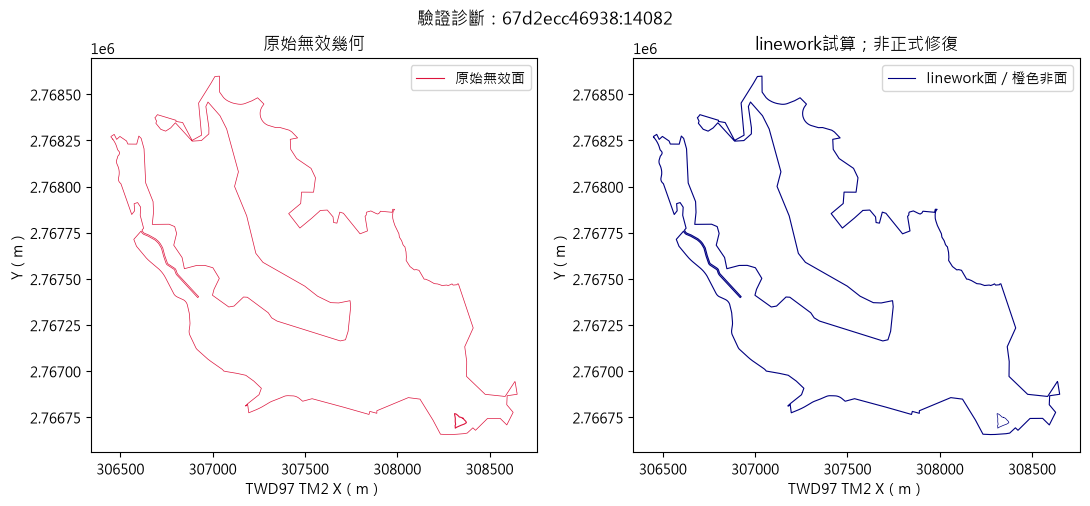

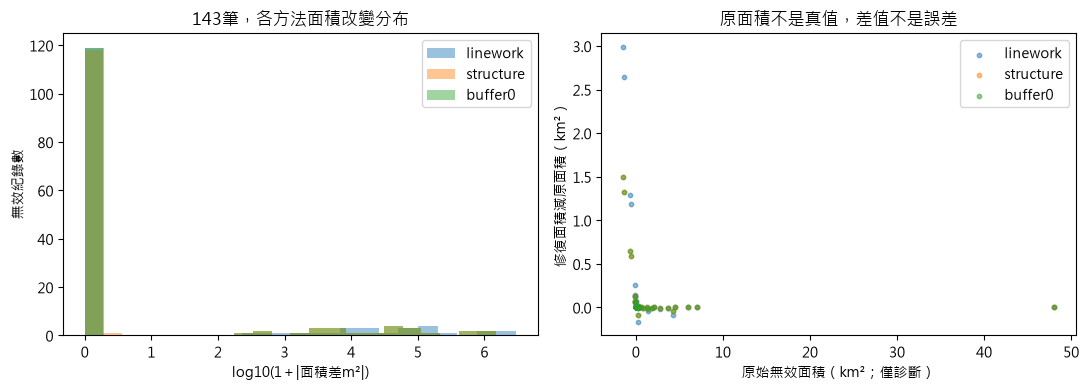

In [7]:
# Illustrative worst record and nonpolygon remnants, raw vertices drawn without repairing them.
chosen=int(method_diff.sort_values('linework_structure_symdiff_m2',ascending=False).iloc[0].record_1based)-1
def draw_parts(ax,g,color,label,fill=False):
    pp,rem=parts(g)
    for j,p in enumerate(pp):
        x,y=p.exterior.xy;ax.plot(x,y,color=color,lw=.8,label=label if j==0 else None)
        if fill:ax.fill(x,y,color=color,alpha=.15)
        for ring in p.interiors:x,y=ring.xy;ax.plot(x,y,color=color,lw=.5)
    for p in rem:
        if p.geom_type=='LineString':x,y=p.xy;ax.plot(x,y,color='orange',lw=2)
fig,axs=plt.subplots(1,2,figsize=(11,5))
draw_parts(axs[0],geom[chosen],'crimson','原始無效面')
draw_parts(axs[1],trials['linework'][list(bad).index(chosen)],'navy','linework面／橙色非面')
for ax,title in zip(axs,['原始無效幾何','linework試算；非正式修復']):ax.set(title=title,xlabel='TWD97 TM2 X（m）',ylabel='Y（m）');ax.set_aspect('equal');ax.legend()
fig.suptitle('驗證診斷：'+raw_ids[chosen]);finish(fig,'01_invalid_before_after')
fig,axs=plt.subplots(1,2,figsize=(11,4))
for method in trials:
    d=repairs[repairs.method.eq(method)]
    axs[0].hist(np.log10(1+abs(d.delta_m2)),bins=22,alpha=.45,label=method)
    axs[1].scatter(d.original_area_m2/1e6,d.delta_m2/1e6,s=10,alpha=.5,label=method)
axs[0].set(xlabel='log10(1＋|面積差m²|)',ylabel='無效紀錄數',title='143筆，各方法面積改變分布')
axs[1].set(xlabel='原始無效面積（km²；僅診斷）',ylabel='修復面積減原面積（km²）',title='原面積不是真值，差值不是誤差')
for ax in axs:ax.legend()
finish(fig,'02_repair_area_differences')


## 4. Exact and spatially equivalent duplicates
先按原始WKB分組，另用STRtree找原始bounds相交候選，再比對有效診斷面是否空間equals，並分開標示是否原本有效、修復是否新增等價。A比較除單筆識別「編號」之外所有原始屬性；編號逐筆保留，不宣稱全欄逐字一致。B同研究類但屬性不同；C跨研究類；D範圍邊界。沒有刪除任何列。


**原始WKB五組十一列，全部原始屬性**

,group,source_record_id,record_1based,kind,編號,圖層,顏色,街廓編號,分區代碼,分區簡稱,使用分區,分區說明,原屬分區,變更前代碼,變更前簡稱,變更前分區,research_category
0,1,67d2ecc46938:00001,1,D_non_zoning_boundary,1,368,0,,細部計畫範圍,細部計畫範圍,,,,,,,non_zoning_boundary
1,1,67d2ecc46938:00002,2,D_non_zoning_boundary,2,370,0,,規劃範圍,規劃範圍,,,,,,,non_zoning_boundary
2,1,67d2ecc46938:00003,3,D_non_zoning_boundary,3,370,0,,規劃範圍,規劃範圍,,,,,,,non_zoning_boundary
3,2,67d2ecc46938:13259,13259,A_same_geometry_and_attributes_except_record_identifier,13259,17,3,,B3A,商三特,第三種商業區(特),,,,,,commercial
4,2,67d2ecc46938:13261,13261,A_same_geometry_and_attributes_except_record_identifier,13261,17,3,,B3A,商三特,第三種商業區(特),,,,,,commercial
5,3,67d2ecc46938:14497,14497,A_same_geometry_and_attributes_except_record_identifier,14497,41,10,,PSF7,藝術大學,國立臺北藝術大學用地,,,,,,educational
6,3,67d2ecc46938:14498,14498,A_same_geometry_and_attributes_except_record_identifier,14498,41,10,,PSF7,藝術大學,國立臺北藝術大學用地,,,,,,educational
7,4,67d2ecc46938:14542,14542,A_same_geometry_and_attributes_except_record_identifier,14542,5,4,,R3A,住3(特),第三種住宅區(特),,,,,,residential
8,4,67d2ecc46938:14562,14562,A_same_geometry_and_attributes_except_record_identifier,14562,5,4,,R3A,住3(特),第三種住宅區(特),,,,,,residential
9,5,67d2ecc46938:15192,15192,A_same_geometry_and_attributes_except_record_identifier,15192,49,13,,PFD1,抽,抽水站用地,,,,,,other_public_facilities


{'indexed_intersecting_candidate_pairs': 56584, 'unindexed_all_pairs_avoided': 120396403}


**所有空間等價pair；可能包含修復後等價，非新增原始完全重複組**

,record_a,record_b,category_a,category_b,raw_exact_wkb,both_original_valid,kind
0,1,3,non_zoning_boundary,non_zoning_boundary,True,True,D_non_zoning_boundary
1,1,2,non_zoning_boundary,non_zoning_boundary,True,True,D_non_zoning_boundary
2,2,3,non_zoning_boundary,non_zoning_boundary,True,True,D_non_zoning_boundary
3,13259,13261,commercial,commercial,True,True,A_same_geometry_and_attributes_except_record_identifier
4,14450,14454,residential,park_green,False,True,C_cross_category
5,14497,14498,educational,educational,True,True,A_same_geometry_and_attributes_except_record_identifier
6,14542,14562,residential,residential,True,True,A_same_geometry_and_attributes_except_record_identifier
7,15192,15194,other_public_facilities,other_public_facilities,True,True,A_same_geometry_and_attributes_except_record_identifier


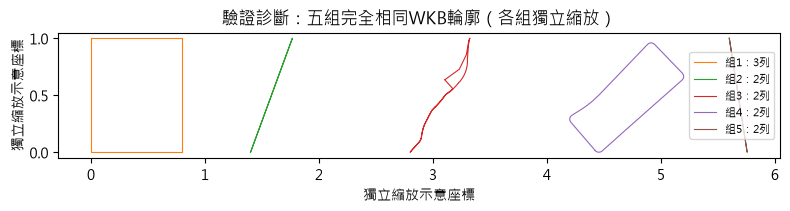

In [8]:
wkb=[bytes(x.wkb) for x in geom];groups={}
for i,k in enumerate(wkb):groups.setdefault(k,[]).append(i)
exact=[v for v in groups.values() if len(v)>1]
assert len(exact)==5 and sum(map(len,exact))==11
all_attrs=list(raw.columns.drop('geometry'));key_attrs=[x for x in all_attrs if x!='編號']
def duplicate_kind(ids):
    if any(boundary[ids]):return 'D_non_zoning_boundary'
    if len(set(category[ids]))>1:return 'C_cross_category'
    if raw.iloc[ids][key_attrs].fillna('').drop_duplicates().shape[0]==1:return 'A_same_geometry_and_attributes_except_record_identifier'
    return 'B_same_category_different_attributes'
duplicate_rows=[]
for group_id,ids in enumerate(exact,1):
    for i in ids:duplicate_rows.append(dict(group=group_id,source_record_id=raw_ids[i],record_1based=i+1,kind=duplicate_kind(np.array(ids)),**raw.iloc[i][all_attrs].fillna('').to_dict(),research_category=category[i]))
duplicate_table=pd.DataFrame(duplicate_rows);show('原始WKB五組十一列，全部原始屬性',duplicate_table)
tree=s.STRtree(reference);pair=tree.query(reference,predicate='intersects');left,right=pair[:,pair[0]<pair[1]]
print({'indexed_intersecting_candidate_pairs':len(left),'unindexed_all_pairs_avoided':len(raw)*(len(raw)-1)//2})
equiv=[]
for start in range(0,len(left),10000):
    a=left[start:start+10000];b=right[start:start+10000]
    eq=s.equals(reference[a],reference[b])
    for i,j in zip(a[eq],b[eq]):equiv.append(dict(record_a=int(i+1),record_b=int(j+1),category_a=category[i],category_b=category[j],raw_exact_wkb=wkb[i]==wkb[j],both_original_valid=bool(geom[i].is_valid and geom[j].is_valid),kind=duplicate_kind(np.array([i,j]))))
equivalent=pd.DataFrame(equiv);show('所有空間等價pair；可能包含修復後等價，非新增原始完全重複組',equivalent)
fig,ax=plt.subplots(figsize=(8,5))
for group_id,ids in enumerate(exact,1):
    # Local geometry shapes separately normalized for visibility; no inference on location.
    p=reference[ids[0]];minx,miny,maxx,maxy=p.bounds
    from shapely.affinity import translate,scale
    q=scale(translate(p,xoff=-minx,yoff=-miny),xfact=1/max(maxx-minx,maxy-miny),yfact=1/max(maxx-minx,maxy-miny),origin=(0,0))
    q=translate(q,xoff=(group_id-1)*1.4)
    draw_parts(ax,q,plt.cm.tab10(group_id),f'組{group_id}：'+str(len(ids))+'列')
ax.set(title='驗證診斷：五組完全相同WKB輪廓（各組獨立縮放）',xlabel='獨立縮放示意座標',ylabel='獨立縮放示意座標');ax.set_aspect('equal');ax.legend(fontsize=8)
finish(fig,'03_exact_duplicates')


## 5. Indexed partial-overlap diagnostics
使用記憶體linework面構件參考，STRtree相交候選後逐批intersection，不做全組合。面積大於0為正面積重疊；等於0的線／點接觸分開。0、0.01、1、10、100m²為敏感度門檻，只描述微碎片，不裁切、snap、刪除或決定法定優先。兩兩面積加總可能多次計入三重以上覆蓋，另以類別聯集計算唯一跨類範圍。


**接觸與重疊分類統計**

,kind,relation,pairs,pairwise_area_sum_m2
0,ambiguous_vs_classified,point_touch,1,0.000000e+00
1,ambiguous_vs_classified,positive_area,18,4.779198e+01
2,ambiguous_vs_classified,shared_line,7,0.000000e+00
3,boundary_involved,positive_area,46548,3.070052e+09
4,cross_category,point_touch,694,0.000000e+00
5,cross_category,positive_area,1272,9.101922e+02
6,cross_category,shared_line,4263,0.000000e+00
7,same_category,point_touch,473,0.000000e+00
8,same_category,positive_area,716,2.168270e+04
9,same_category,shared_line,2592,0.000000e+00


,threshold_m2,scope,positive_pairs,pairwise_area_sum_m2
0,0.00,all_including_boundaries,48554,3.070074e+09
1,0.00,exclude_boundaries,2006,2.264068e+04
2,0.01,all_including_boundaries,47307,3.070074e+09
3,0.01,exclude_boundaries,813,2.264024e+04
4,1.00,all_including_boundaries,46787,3.070074e+09
5,1.00,exclude_boundaries,320,2.246521e+04
6,10.00,all_including_boundaries,46435,3.070073e+09
7,10.00,exclude_boundaries,25,2.163663e+04
8,100.00,all_including_boundaries,45856,3.070042e+09
9,100.00,exclude_boundaries,4,2.112409e+04


,kind,0.0,0.25,0.5,0.75,0.95,1.0
0,ambiguous_vs_classified,5.109178e-10,9.053490e-04,0.053910,0.570749,12.322542,3.468182e+01
1,boundary_involved,3.178173e-07,1.390075e+03,2989.612897,5277.562869,24092.740366,7.739873e+08
2,cross_category,8.131516e-20,6.984229e-09,0.000027,0.383685,2.997983,7.751201e+01
3,same_category,3.613510e-16,3.014947e-08,0.000312,0.459528,3.649351,9.396240e+03


**全部類別組合（pairwise面積不可當唯一面積）**

,kind,category_pair,positive_pairs,pairwise_area_sum_m2,max_pair_m2
56,same_category,educational × educational,24,9408.037315,9396.239594
62,same_category,residential × residential,278,5942.299339,5195.780761
61,same_category,park_green × park_green,59,5935.105180,5909.431313
64,same_category,water × water,92,206.695563,42.461701
47,cross_category,other_public_facilities × water,64,169.975514,16.766975
50,cross_category,park_green × water,47,138.522385,77.512010
54,same_category,agriculture_conservation × agriculture_conservation,34,112.950049,32.228631
44,cross_category,other_public_facilities × park_green,42,95.321576,34.251026
11,cross_category,agriculture_conservation × park_green,32,74.974423,41.277622
14,cross_category,agriculture_conservation × water,18,57.774337,17.175492


... (2 outputs left out)

,kind,category_pair,positive_pairs,pairwise_area_sum_m2,max_pair_m2
38,cross_category,mixed_special_use × transportation,8,1.338977e-04,1.331472e-04
57,same_category,industrial × industrial,2,1.147000e-04,1.146703e-04
34,cross_category,mixed_special_use × other_classified,2,9.997767e-05,9.991827e-05
17,cross_category,commercial × mixed_special_use,22,6.202758e-05,5.923152e-05
23,cross_category,educational × mixed_special_use,1,1.704442e-05,1.704442e-05
15,cross_category,commercial × educational,3,6.977168e-07,5.764606e-07
16,cross_category,commercial × industrial,3,6.922090e-07,4.251711e-07
9,cross_category,agriculture_conservation × other_classified,4,6.124180e-07,2.520061e-07
42,cross_category,other_classified × residential,3,8.257199e-08,6.930428e-08
29,cross_category,industrial × mixed_special_use,2,2.290963e-10,2.289906e-10


**排除範圍後主要25對重疊及來源列號**

,a,b,record_a,record_b,category_pair,kind,relation,area_m2,length_m
55795,14496,14497,14497,14498,educational × educational,same_category,positive_area,9396.239594,1591.383536
50321,2552,2557,2553,2558,park_green × park_green,same_category,positive_area,5909.431313,466.534469
55852,14541,14561,14542,14562,residential × residential,same_category,positive_area,5195.780761,315.836084
56236,15001,15122,15002,15123,residential × residential,same_category,positive_area,622.642135,120.757279
50000,2340,10287,2341,10288,park_green × water,cross_category,positive_area,77.512010,630.355815
50584,2672,11677,2673,11678,water × water,same_category,positive_area,42.461701,481.216225
50002,2341,9377,2342,9378,agriculture_conservation × park_green,cross_category,positive_area,41.277622,642.919468
49688,2206,2220,2207,2221,other_public_facilities × unclassified,ambiguous_vs_classified,positive_area,34.681824,1660.341932
54657,13379,13380,13380,13381,other_public_facilities × park_green,cross_category,positive_area,34.251026,577.165335
54490,12737,14657,12738,14658,agriculture_conservation × agriculture_conservation,same_category,positive_area,32.228631,29.266538


,a,b,record_a,record_b,category_pair,kind,relation,area_m2,length_m
50612,2684,9377,2685,9378,agriculture_conservation × water,cross_category,positive_area,14.113869,19.146432
55292,13879,13884,13880,13885,other_public_facilities × water,cross_category,positive_area,14.097440,1183.617908
55183,13782,13783,13783,13784,other_public_facilities × park_green,cross_category,positive_area,12.281664,1708.159883
54954,13630,13636,13631,13637,other_public_facilities × water,cross_category,positive_area,12.057159,985.795533
54488,12736,14656,12737,14657,residential × residential,same_category,positive_area,10.677241,19.625103
55178,13782,13788,13783,13789,other_public_facilities × water,cross_category,positive_area,10.354475,1451.586230
48963,1752,1753,1753,1754,park_green × park_green,same_category,positive_area,10.297515,220.396395


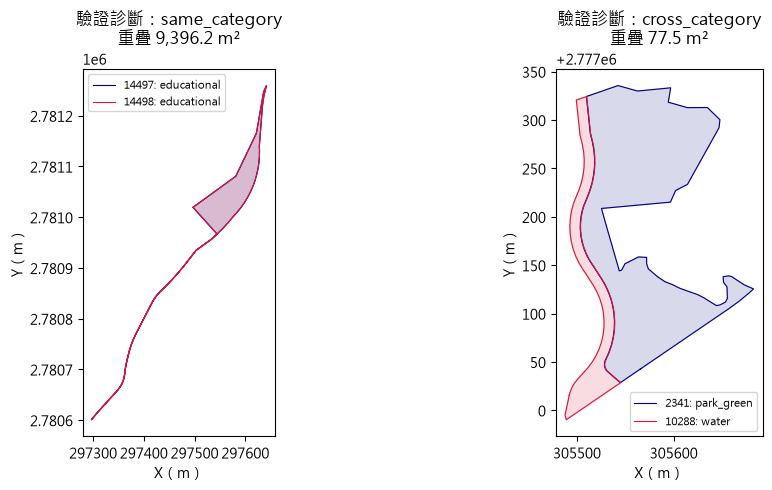

In [9]:
pair_rows=[]
for start in range(0,len(left),5000):
    a=left[start:start+5000];b=right[start:start+5000]
    intersections=s.intersection(reference[a],reference[b]);areas=s.area(intersections);lengths=s.length(intersections)
    for i,j,area,length,inter in zip(a,b,areas,lengths,intersections):
        if inter.is_empty:continue
        kind='boundary_involved' if boundary[i] or boundary[j] else 'ambiguous_vs_classified' if ambiguous[i]!=ambiguous[j] else 'ambiguous_with_ambiguous' if ambiguous[i] else 'same_category' if category[i]==category[j] else 'cross_category'
        pair_rows.append(dict(a=int(i),b=int(j),record_a=int(i+1),record_b=int(j+1),category_pair=' × '.join(sorted([category[i],category[j]])),kind=kind,relation='positive_area' if area>0 else 'shared_line' if length>0 else 'point_touch',area_m2=float(area),length_m=float(length)))
pairs=pd.DataFrame(pair_rows);positive=pairs[pairs.relation.eq('positive_area')]
show('接觸與重疊分類統計',pairs.groupby(['kind','relation']).agg(pairs=('a','size'),pairwise_area_sum_m2=('area_m2','sum')).reset_index())
tolerance=[]
for threshold in [0,.01,1,10,100]:
    for scope,mask in [('all_including_boundaries',np.ones(len(pairs),bool)),('exclude_boundaries',~pairs.kind.eq('boundary_involved'))]:
        d=pairs[mask & pairs.area_m2.gt(threshold)]
        tolerance.append(dict(threshold_m2=threshold,scope=scope,positive_pairs=len(d),pairwise_area_sum_m2=d.area_m2.sum()))
tolerance=pd.DataFrame(tolerance);display(tolerance)
quantiles=positive.groupby('kind').area_m2.quantile([0,.25,.5,.75,.95,1]).unstack().reset_index();display(quantiles)
class_pairs=positive[~positive.kind.eq('boundary_involved')].groupby(['kind','category_pair']).agg(positive_pairs=('a','size'),pairwise_area_sum_m2=('area_m2','sum'),max_pair_m2=('area_m2','max')).reset_index().sort_values('pairwise_area_sum_m2',ascending=False)
show('全部類別組合（pairwise面積不可當唯一面積）',class_pairs)
main_overlaps=positive[~positive.kind.eq('boundary_involved')].sort_values('area_m2',ascending=False).head(25)
show('排除範圍後主要25對重疊及來源列號',main_overlaps)
fig,axs=plt.subplots(1,2,figsize=(11,5))
examples=[]
for kind in ['same_category','cross_category']:
    d=positive[positive.kind.eq(kind)].sort_values('area_m2',ascending=False)
    if len(d):examples.append(d.iloc[0])
for ax,row in zip(axs,examples):
    i,j=int(row.a),int(row.b);draw_parts(ax,reference[i],'navy',f'{i+1}: {category[i]}',True);draw_parts(ax,reference[j],'crimson',f'{j+1}: {category[j]}',True)
    ax.set(title=f'驗證診斷：{row.kind}\n重疊 {row.area_m2:,.1f} m²',xlabel='X（m）',ylabel='Y（m）');ax.set_aspect('equal');ax.legend(fontsize=8)
finish(fig,'04_same_cross_overlap')


## 6. City-level coverage and nonexclusive sets
同類先union，防止完全及部分重複計數；跨類未知優先序不任意覆蓋。這裡以每類聯集兩兩intersection再union，計唯一跨類不確定範圍。分類完成及未分類的覆蓋可能重疊，不直接相加。保留陽明山公園待確認面；它不算已認證eligible，但另報含它的候選覆蓋及未知面積，沒有當成非分區丟棄。


,set,area_m2,meaning,area_km2,ratio_of_city
0,research_city,2.685501e+08,固定456里聯集；不逐里疊合,268.550083,1.000000e+00
1,eligible_zoning_union_inside,1.957539e+08,本次已分類eligible之聯集,195.753924,7.289289e-01
2,classified_union_inside,1.957539e+08,本次eligible均有研究類別，與上一列同集合,195.753924,7.289289e-01
3,candidate_union_including_ambiguous_inside,2.436794e+08,保留陽明山公園待確認面之候選覆蓋,243.679422,9.073891e-01
4,unclassified_union_inside,4.792555e+07,可與已分類重疊，不直接相加,47.925545,1.784604e-01
5,unclassified_only_inside,4.792550e+07,未知扣除已分類後，可加到已分類覆蓋,47.925497,1.784602e-01
6,unresolved_cross_category_inside,9.097846e+02,已分類類別間唯一重疊聯集,0.000910,3.387765e-06
7,classified_vs_unclassified_inside,4.779198e+01,另一獨立不確定集合，可能與跨類集合重疊,0.000048,1.779630e-07
8,uncovered_by_all_candidate_inside,2.487066e+07,未被任何候選分區面覆蓋，非零住宅證據,24.870661,9.261089e-02
9,uncovered_by_eligible_inside,7.279616e+07,含未知獨占及全候選未覆蓋，避免混淆,72.796158,2.710711e-01


**分類鍵數／原始筆數／診斷面積；原始及修復加總都可能重複，不是正式分區面積**

,research_zoning_category,compound_keys,raw_records,single_codes,raw_area_sum_diagnostic_km2,linework_area_sum_diagnostic_km2,within_class_union_km2
0,agriculture_conservation,2,285,2,70.919352,75.189747,75.189635
1,commercial,23,2904,17,9.027458,9.027458,9.027420
2,educational,35,425,34,11.388446,11.512308,11.502903
3,industrial,16,217,13,3.856919,3.931232,3.931232
4,mixed_special_use,55,540,47,2.830596,2.830596,2.830591
5,non_zoning_boundary,2,3,2,2321.961992,2321.961992,NaN
6,other_classified,12,95,9,0.469135,3.113979,3.113979
7,other_public_facilities,85,1134,80,15.401482,16.597334,16.597309
8,park_green,9,1286,6,12.320750,12.436476,12.430541
9,residential,29,7737,27,37.226175,37.573221,37.567279


,keys,raw_records
verification_status,,
ambiguous,1,1
excluded_non_zoning,2,3
official_supported,18,8468
research_classification,275,7046


**類別聯集跨類重疊，單一組合內已去同類重複**

,category_a,category_b,unique_within_pair_m2,inside_city_m2
41,other_public_facilities,water,169.975479,169.975479
44,park_green,water,138.530345,138.530345
38,other_public_facilities,park_green,95.010623,95.010623
5,agriculture_conservation,park_green,74.974423,74.974423
8,agriculture_conservation,water,57.774337,57.774337
42,park_green,residential,50.404348,50.404348
46,residential,water,43.286941,43.286941
40,other_public_facilities,transportation,36.017846,36.017846
7,agriculture_conservation,transportation,34.316454,34.316454
45,residential,transportation,32.340452,32.340452


,category_a,category_b,unique_within_pair_m2,inside_city_m2
25,industrial,park_green,6.603984,6.603984
18,educational,other_public_facilities,6.527103,6.527103
30,mixed_special_use,park_green,4.848826,4.848826
0,agriculture_conservation,educational,4.547384,4.547384
26,industrial,transportation,4.054969,4.054969
19,educational,park_green,3.967632,3.967632
33,mixed_special_use,water,3.868750,3.868750
21,educational,transportation,3.174496,3.174496
31,mixed_special_use,residential,3.019357,3.019357
24,industrial,other_public_facilities,2.330145,2.330145


,category_a,category_b,unique_within_pair_m2,inside_city_m2
20,educational,residential,4.205231e-01,4.205231e-01
37,other_classified,transportation,8.353945e-03,8.353945e-03
32,mixed_special_use,transportation,1.338969e-04,1.338969e-04
28,mixed_special_use,other_classified,9.997767e-05,9.997767e-05
11,commercial,mixed_special_use,6.203043e-05,6.203043e-05
17,educational,mixed_special_use,1.704442e-05,1.704442e-05
9,commercial,educational,6.977168e-07,6.977168e-07
10,commercial,industrial,6.922090e-07,6.922090e-07
3,agriculture_conservation,other_classified,3.612727e-07,3.612727e-07
36,other_classified,residential,8.257199e-08,8.257199e-08


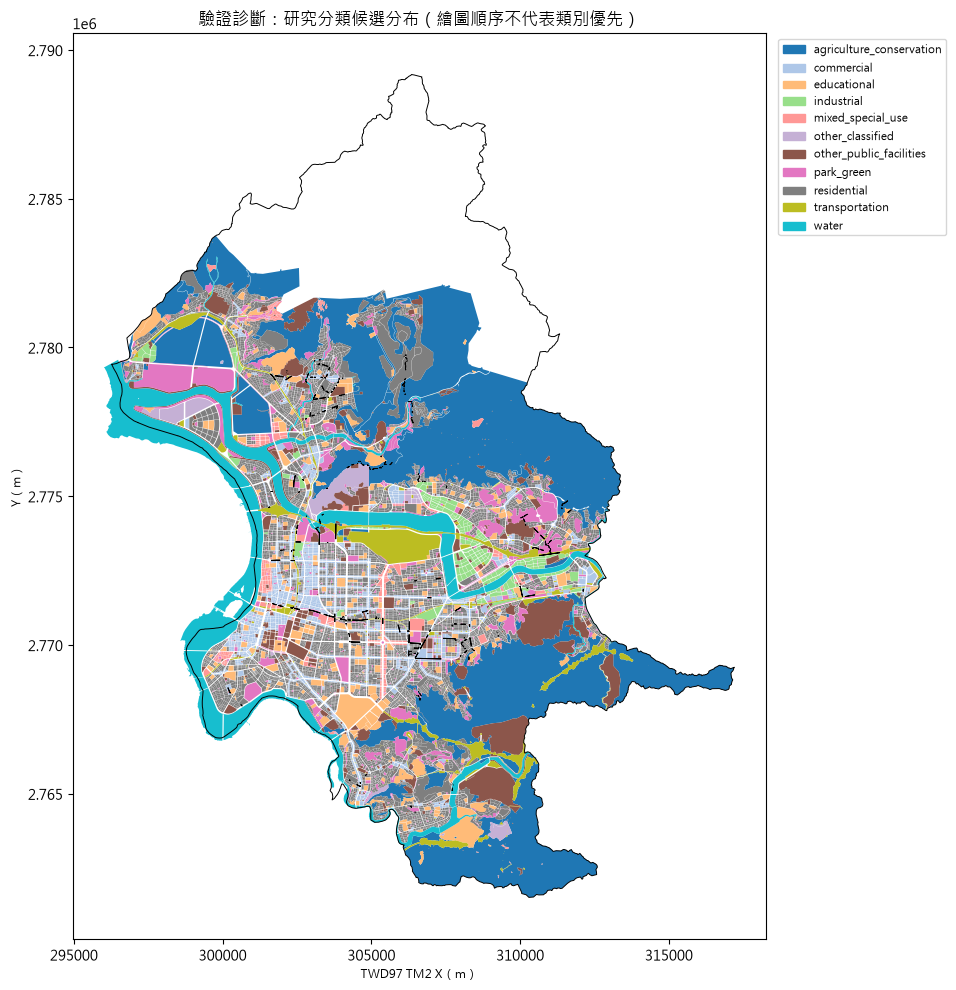

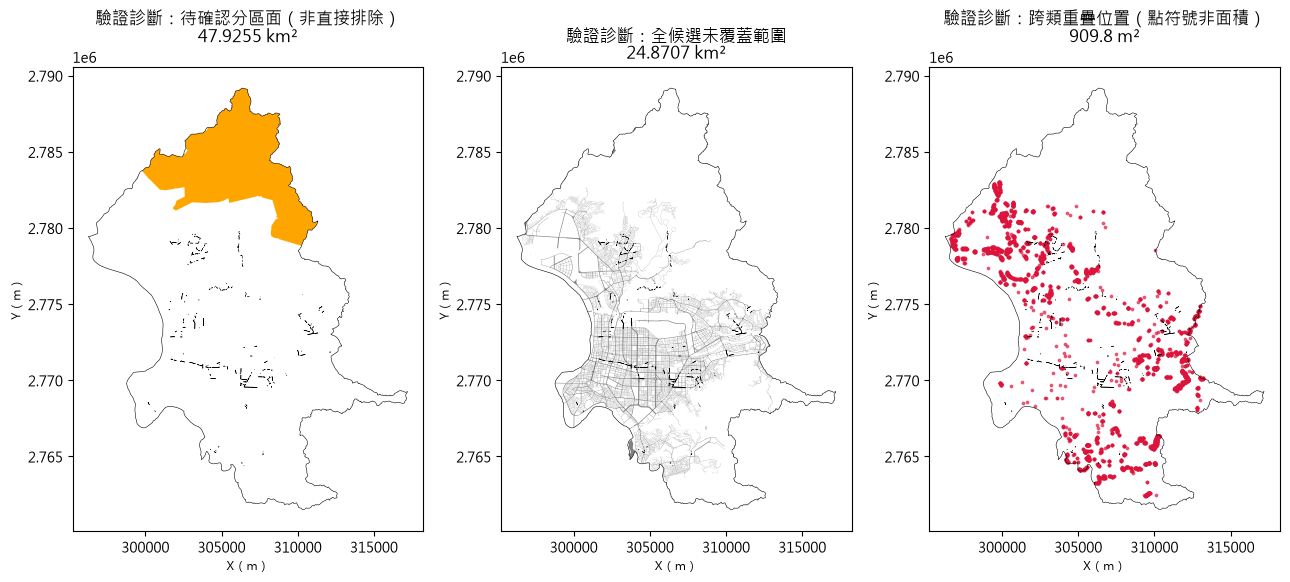

In [10]:
categories=sorted(set(category)-{'non_zoning_boundary','unclassified'})
class_unions={c:s.union_all(reference[category==c]) for c in categories}
classified=s.union_all(list(class_unions.values()));unknown=s.union_all(reference[ambiguous]);candidate=s.union_all([classified,unknown])
cross_parts=[];cross_class_rows=[]
for i,c in enumerate(categories):
    for d in categories[i+1:]:
        inter=class_unions[c].intersection(class_unions[d])
        if inter.area>0:cross_parts.append(inter);cross_class_rows.append(dict(category_a=c,category_b=d,unique_within_pair_m2=inter.area,inside_city_m2=inter.intersection(city).area))
cross_unresolved=s.union_all(cross_parts)
uncovered=city.difference(candidate)
known_uncovered=city.difference(classified)
unknown_inside=unknown.intersection(city);unknown_exclusive=unknown.difference(classified).intersection(city)
coverage=pd.DataFrame([
 ('research_city',city.area,'固定456里聯集；不逐里疊合'),
 ('eligible_zoning_union_inside',classified.intersection(city).area,'本次已分類eligible之聯集'),
 ('classified_union_inside',classified.intersection(city).area,'本次eligible均有研究類別，與上一列同集合'),
 ('candidate_union_including_ambiguous_inside',candidate.intersection(city).area,'保留陽明山公園待確認面之候選覆蓋'),
 ('unclassified_union_inside',unknown_inside.area,'可與已分類重疊，不直接相加'),
 ('unclassified_only_inside',unknown_exclusive.area,'未知扣除已分類後，可加到已分類覆蓋'),
 ('unresolved_cross_category_inside',cross_unresolved.intersection(city).area,'已分類類別間唯一重疊聯集'),
 ('classified_vs_unclassified_inside',classified.intersection(unknown).intersection(city).area,'另一獨立不確定集合，可能與跨類集合重疊'),
 ('uncovered_by_all_candidate_inside',uncovered.area,'未被任何候選分區面覆蓋，非零住宅證據'),
 ('uncovered_by_eligible_inside',known_uncovered.area,'含未知獨占及全候選未覆蓋，避免混淆'),
 ('candidate_outside_city',candidate.difference(city).area,'不裁改原來源；只作研究區外診斷'),
 ('eligible_outside_city',classified.difference(city).area,'已分類候選超出固定研究範圍')],columns=['set','area_m2','meaning'])
coverage['area_km2']=coverage.area_m2/1e6;coverage['ratio_of_city']=coverage.area_m2/city.area
display(coverage)
assert abs(candidate.intersection(city).area+uncovered.area-city.area)<.01
assert abs(classified.intersection(city).area+unknown_exclusive.area+uncovered.area-city.area)<.01
cat_summary=crosswalk.groupby('research_zoning_category').agg(compound_keys=('original_record_count','size'),raw_records=('original_record_count','sum')).reset_index()
cat_summary['single_codes']=cat_summary.research_zoning_category.map(crosswalk.groupby('research_zoning_category').original_zoning_code.nunique())
cat_summary['raw_area_sum_diagnostic_km2']=cat_summary.research_zoning_category.map({c:float(s.area(geom[category==c]).sum())/1e6 for c in set(category)})
cat_summary['linework_area_sum_diagnostic_km2']=cat_summary.research_zoning_category.map({c:float(s.area(reference[category==c]).sum())/1e6 for c in set(category)})
cat_summary['within_class_union_km2']=cat_summary.research_zoning_category.map({c:g.area/1e6 for c,g in class_unions.items()})
show('分類鍵數／原始筆數／診斷面積；原始及修復加總都可能重複，不是正式分區面積',cat_summary)
display(crosswalk.groupby('verification_status').agg(keys=('original_record_count','size'),raw_records=('original_record_count','sum')))
show('類別聯集跨類重疊，單一組合內已去同類重複',pd.DataFrame(cross_class_rows).sort_values('inside_city_m2',ascending=False))
fig,ax=plt.subplots(figsize=(9,10))
colors={c:plt.cm.tab20(i/len(categories)) for i,c in enumerate(categories)}
for c in categories:gpd.GeoSeries([class_unions[c]],crs=3826).plot(ax=ax,color=colors[c],linewidth=0,label=c)
gpd.GeoSeries([city],crs=3826).boundary.plot(ax=ax,color='black',linewidth=.7)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=colors[c],label=c) for c in categories],loc='upper left',bbox_to_anchor=(1.01,1),fontsize=8)
ax.set(title='驗證診斷：研究分類候選分布（繪圖順序不代表類別優先）',xlabel='TWD97 TM2 X（m）',ylabel='Y（m）');finish(fig,'05_zoning_overview')
fig,axs=plt.subplots(1,3,figsize=(13,6))
for ax,g,title,color in zip(axs,[unknown_inside,uncovered,cross_unresolved.intersection(city)],['待確認分區面（非直接排除）','全候選未覆蓋範圍','唯一跨類待確認重疊'],['orange','gray','crimson']):
    gpd.GeoSeries([city],crs=3826).boundary.plot(ax=ax,color='black',linewidth=.4)
    if not g.is_empty:
        plot_area=polygon_part(g)
        if color=='crimson':
            # Tiny positive-area overlaps are shown as explicit position symbols.
            # Do not let zero-area line/point remnants render as area-sized circles.
            locations=gpd.GeoSeries([plot_area],crs=3826).explode(index_parts=False).representative_point()
            locations.plot(ax=ax,color=color,markersize=3,alpha=.6)
            title='跨類重疊位置（點符號非面積）'
        else:gpd.GeoSeries([plot_area],crs=3826).plot(ax=ax,color=color,linewidth=0)
    amount=f'{g.area:,.1f} m²' if color=='crimson' else f'{g.area/1e6:.4f} km²'
    ax.set(title=f'驗證診斷：{title}\n{amount}',xlabel='X（m）',ylabel='Y（m）')
finish(fig,'06_coverage_quality')


## 7. Proposed area accounting and Dataset B2 — pending student review
**推薦方案B**：同類先聯集。跨研究類重疊聯集`U_cross`不武斷分派；並將已分類與未知圖層相交`U_amb`保留為另一不確定集合。若採互斥保守特徵，`E_c = Union(class c) \ (U_cross ∪ U_amb)`。不得為湊足100%刪未覆蓋、重新正規化或指定住宅優於商業。

**A官方優先序**：本次法規／metadata沒有足夠證據決定本機每個重疊面的核定版本及優先序，故不採。將來有逐案生效證據才可另審。
**C非互斥覆蓋比例**：`E_c = Union(class c)`，重疊各類可重複覆蓋，合計可能超過100%；必須明確改名／定義為非互斥覆蓋並保留品質指標。本次只比較規則，不輸出逐里資料。

主要候選共同公式：`ratio_c(v) = Area(E_c ∩ V_v) / Area(V_v)`，面積皆EPSG:3826，m²同除或km²同除，單位0–1比例；分母為固定原始里幾何面積而非人口、全市或已覆蓋面積。456里含糖廍均同規則。里界原有細微拓樸限制不在本單元修正。

|主要候選／中文|研究類別與原始欄位|分子／限制|
|---|---|---|
|residential_zoning_ratio／住宅分區面積比|residential；圖層、分區代碼、使用分區、分區說明、分區簡稱|經審查E_residential與固定里交集；特定專用住宅不逕併入|
|commercial_zoning_ratio／商業分區面積比|commercial；相同五原始欄位|E_commercial；B指定展會與BAA辦公服務等研究寬類需審|
|industrial_zoning_ratio／工業分區面積比|industrial；相同五原始欄位|E_industrial；IF產業服務等邊界分類需審|
|educational_zoning_ratio／文教學校分區面積比|educational；相同五原始欄位|E_educational；文教不等於實際學生人流|
|park_green_zoning_ratio／公園綠地分區面積比|park_green；相同五原始欄位|E_park_green；不把風景、一般廣場、陽明山公園待確認面自動視為綠地|

五類均有原始紀錄，可定義候選；尚未通過正式修復／跨類規則與品質審查，不能宣稱已具完整456里可比較的正式比例。資料缺漏、未覆蓋與未分類不是該類不存在；低品質里之數值保留NA或附品質旗標與審查後可用規則，不能直接補零。是否全里NA、特定類NA、最低覆蓋門檻尚待學生審查；目前未設任意門檻。確有充分覆蓋而某類有效交集為零才有零值語義。

獨立品質指標（非環境分群主要特徵）：`zoning_coverage_ratio=Area(V∩Union(eligible))/Area(V)`；`unclassified_area_ratio=Area(V∩Union(ambiguous))/Area(V)`；`unresolved_overlap_ratio=Area(V∩(U_cross∪U_amb))/Area(V)`；`uncovered_area_ratio=Area(V\Union(eligible∪ambiguous))/Area(V)`。另留含未知候選coverage，以免將未知直接當未覆蓋；品質集合可能相交不可相加。全部逐里定義僅文件，本次未計算。

補充候選transportation、agriculture_conservation、other_public_facilities可按同公式另審，不擴成當前主要特徵。用途分區是都市計畫指定，非實際土地使用、道路密度、道路長度、交通流量或人流；固定快照的生效／歷史適用未知，不當作2024及2025年度環境變動或因果證據。下一步先確認幾何例外、分類及面積規則，再決定Unit 1.6資料整合，不能跳過事故datum／歸里等獨立待辦。


In [11]:
main=['residential','commercial','industrial','educational','park_green']
uncertain_union=s.union_all([cross_unresolved,classified.intersection(unknown)])
comparison=[]
for c in main:
    base=class_unions[c].intersection(city);effective=base.difference(uncertain_union)
    comparison.append(dict(category=c,nonexclusive_C_city_km2=base.area/1e6,conservative_B_city_km2=effective.area/1e6,withheld_uncertainty_km2=(base.area-effective.area)/1e6,raw_records=int((category==c).sum())))
display(pd.DataFrame(comparison))
print('只比較全市候選面積，未建立逐里E_c、Overlay、B2或品質比例。')


,category,nonexclusive_C_city_km2,conservative_B_city_km2,withheld_uncertainty_km2,raw_records
0,residential,37.558326,37.558147,0.000179,7737
1,commercial,9.027420,9.027382,0.000038,2904
2,industrial,3.931232,3.931218,0.000015,217
3,educational,11.501814,11.501783,0.000031,425
4,park_green,12.427845,12.427450,0.000395,1286


只比較全市候選面積，未建立逐里E_c、Overlay、B2或品質比例。


## 8. Save the classification crosswalk, reopen and verify
僅新分類對照CSV，UTF-8-SIG；五欄複合鍵原始字串（含換行）保留，原始缺值於表內以空字串表示並由eligibility／verification區分，不覆寫來源。重跑若已有輸出，僅接受完全相同bytes，否則停止；不默默替換其他版本。


In [12]:
out=ROOT/'data/processed/urban_zoning_crosswalk.csv'
assert out.resolve().is_relative_to((ROOT/'data/processed').resolve())
payload=crosswalk.to_csv(index=False,lineterminator='\n').encode('utf-8-sig')
if out.exists():assert out.read_bytes()==payload,'Existing crosswalk differs; review version, do not overwrite'
else:out.write_bytes(payload)
saved=pd.read_csv(out,encoding='utf-8-sig',dtype=str,keep_default_na=False)
assert len(saved)==296 and saved.shape[1]==12
assert not saved.duplicated(OUTKEY).any()
assert saved.original_record_count.str.fullmatch(r'\d+').all()
assert saved.original_record_count.astype(int).sum()==15518
pd.testing.assert_frame_equal(saved,crosswalk.astype(str),check_dtype=False)
assert set(saved.verification_status)=={'official_supported','research_classification','ambiguous','excluded_non_zoning'}
assert saved.loc[saved.research_zoning_category.eq('non_zoning_boundary'),'original_record_count'].astype(int).sum()==3
assert saved.loc[saved.research_zoning_category.eq('unclassified'),'original_record_count'].astype(int).sum()==1
assert raw.crs is None and len(raw)==15518
display(saved.head(10));print('CSV_SHA256',sha(out))
display(verify(EXPECTED_SHA256))
summary={'date':'2026-11-26','working_crs':'EPSG:3826 / B','invalid_reason_counts':diagnosis.validity_reason.str.split('[').str[0].value_counts().to_dict(),'repair_summary':repair_summary.reset_index().to_dict('records'),'review_priority_counts':method_diff.review_priority.value_counts().to_dict(),'exact_duplicate_groups':len(exact),'exact_duplicate_rows':sum(map(len,exact)),'duplicate_kinds':duplicate_table.groupby('group').kind.first().value_counts().to_dict(),'spatial_equivalent_pairs':len(equivalent),'additional_nonWKB_equivalent_pairs':int((~equivalent.raw_exact_wkb).sum()),'indexed_candidates':len(left),'contact_overlap_counts':pairs.groupby(['kind','relation']).size().rename('N').reset_index().to_dict('records'),'tolerance':tolerance.to_dict('records'),'coverage':coverage.to_dict('records'),'category_summary':cat_summary.to_dict('records'),'verification_counts':crosswalk.groupby('verification_status').agg(keys=('original_record_count','size'),raw_records=('original_record_count','sum')).reset_index().to_dict('records'),'crosswalk_hash':sha(out),'source_archive_hash':sha(ROOT/'data/raw/unit15_zoning_classification_evidence.zip'),'main_features_comparison':comparison,'cross_category_combinations':cross_class_rows}
(TEMP/'validation_summary.json').write_text(json.dumps(summary,ensure_ascii=False,indent=2,allow_nan=True),encoding='utf-8')
print('Unit 1.5驗證程式完成；所有正式規則仍依文內待審清單，不自動進入1.6。')


,source_layer_code,original_zoning_code,original_zoning_name,original_zoning_description,original_zoning_abbreviation,research_zoning_category,eligibility_status,classification_method,verification_status,source_evidence,original_record_count,notes
0,1,R1,第一種住宅區,,住1,residential,eligible_zoning,explicit_reviewed_compound_key_v1,official_supported,https://laws.gov.taipei/Law/LawSearch/LawArticleContent/FL003962 第3條；20230804歷史版；原始名稱逐鍵研究映射；unit15證據包,107,明列住宅區／住宅用地之寬類；(特)(遷)與專案住宅仍附條件，未核定細則，不等同容許使用無差別。
1,1,R1A,第一種住宅區(特),,住1(特),residential,eligible_zoning,explicit_reviewed_compound_key_v1,research_classification,https://laws.gov.taipei/Law/LawSearch/LawArticleContent/FL003962 第3條；20230804歷史版；原始名稱逐鍵研究映射；unit15證據包,5,明列住宅區／住宅用地之寬類；(特)(遷)與專案住宅仍附條件，未核定細則，不等同容許使用無差別。
2,10,R,住宅區,,住,residential,eligible_zoning,explicit_reviewed_compound_key_v1,research_classification,https://laws.gov.taipei/Law/LawSearch/LawArticleContent/FL003962 第3條；20230804歷史版；原始名稱逐鍵研究映射；unit15證據包,156,明列住宅區／住宅用地之寬類；(特)(遷)與專案住宅仍附條件，未核定細則，不等同容許使用無差別。
3,10,R5,特定休閒旅館住宅專用區,,休閒,mixed_special_use,eligible_zoning,explicit_reviewed_compound_key_v1,research_classification,https://laws.gov.taipei/Law/LawSearch/LawArticleContent/FL003962 第3條；20230804歷史版；原始名稱逐鍵研究映射；unit15證據包,25,特定專用、混合或聯合開發等獨立類；即使名稱含住商工，不直接併入五主類，個案細則未逐案認證。
4,10,RA,第壹類住宅用地,,住1類,residential,eligible_zoning,explicit_reviewed_compound_key_v1,research_classification,https://laws.gov.taipei/Law/LawSearch/LawArticleContent/FL003962 第3條；20230804歷史版；原始名稱逐鍵研究映射；unit15證據包,3,明列住宅區／住宅用地之寬類；(特)(遷)與專案住宅仍附條件，未核定細則，不等同容許使用無差別。
5,10,RAA,住宅區(特),,住(特),residential,eligible_zoning,explicit_reviewed_compound_key_v1,research_classification,https://laws.gov.taipei/Law/LawSearch/LawArticleContent/FL003962 第3條；20230804歷史版；原始名稱逐鍵研究映射；unit15證據包,8,明列住宅區／住宅用地之寬類；(特)(遷)與專案住宅仍附條件，未核定細則，不等同容許使用無差別。
6,10,RB,第貳類住宅用地,,住2類,residential,eligible_zoning,explicit_reviewed_compound_key_v1,research_classification,https://laws.gov.taipei/Law/LawSearch/LawArticleContent/FL003962 第3條；20230804歷史版；原始名稱逐鍵研究映射；unit15證據包,14,明列住宅區／住宅用地之寬類；(特)(遷)與專案住宅仍附條件，未核定細則，不等同容許使用無差別。
7,10,RC,第參類住宅用地,,住3類,residential,eligible_zoning,explicit_reviewed_compound_key_v1,research_classification,https://laws.gov.taipei/Law/LawSearch/LawArticleContent/FL003962 第3條；20230804歷史版；原始名稱逐鍵研究映射；unit15證據包,18,明列住宅區／住宅用地之寬類；(特)(遷)與專案住宅仍附條件，未核定細則，不等同容許使用無差別。
8,10,RD,駐華使領館辦公暨住宅專用區,,使館住專,mixed_special_use,eligible_zoning,explicit_reviewed_compound_key_v1,research_classification,https://laws.gov.taipei/Law/LawSearch/LawArticleContent/FL003962 第3條；20230804歷史版；原始名稱逐鍵研究映射；unit15證據包,1,特定專用、混合或聯合開發等獨立類；即使名稱含住商工，不直接併入五主類，個案細則未逐案認證。
9,10,REA,特定專用區(三)(供住宅使用),,特(三),mixed_special_use,eligible_zoning,explicit_reviewed_compound_key_v1,research_classification,https://laws.gov.taipei/Law/LawSearch/LawArticleContent/FL003962 第3條；20230804歷史版；原始名稱逐鍵研究映射；unit15證據包,19,特定專用、混合或聯合開發等獨立類；即使名稱含住商工，不直接併入五主類，個案細則未逐案認證。


CSV_SHA256 4326d92d1567167ca67c13dc1c083426bf6d4d789b88ed5da1feec422306383f


,path,bytes,sha256
0,data/raw/細計-面.shp,7556848,67d2ecc469383459e43f2609cf384a4129e09b27c590cbbb82dfa750eba758ee
1,data/raw/細計-面.shx,124244,277e5f623c5c81865aa7288fac979a279b340899a4b3bc4335638f797fc5fd69
2,data/raw/細計-面.dbf,13982136,29b0484feef66c6c8417821ada8a28ed1edc0efcdffb492476fe7ada8739e1d4
3,data/raw/細計-文.shp,184,fa1767fc78c69b7683ec53e0fab8937bac6c33868bedee3c3dcc2ed38dcab731
4,data/raw/細計-文.shx,124,32d642964d494f49d08830f9c12857f9f4995b56eebf09ef2be994034b864760
5,data/raw/細計-文.dbf,3121,eba92881fc11e574f24024380c946d73cf213e86040663c4070d15b1d552a7be
6,data/raw/G97_A_CAVLGE_P.shp,765784,f7fb4813a2283198ca564f5686823c454c5fd832d2f6981a2ee88a94719be3cc
7,data/raw/G97_A_CAVLGE_P.shx,3748,ab7bc5e63229f676d3580b68e98db59b91a2d327c74ca23b0000ca1c568d414e
8,data/raw/G97_A_CAVLGE_P.dbf,272706,2f43f92e84279a45b2512cf453e9b72f706d1ad1402665c946b1a354f75d8577
9,data/raw/G97_A_CAVLGE_P.prj,399,8dac7d82ea889063f9eaa7df408fcaeb7307d32831ea973b6534d0139a4523c5


Unit 1.5驗證程式完成；所有正式規則仍依文內待審清單，不自動進入1.6。


## Verified results and review handoff — 2026-11-26

本次實際執行：143無效＝67 self-intersection＋52 ring self-intersection＋15 hole outside shell＋9 nested shells。linework全部有效且非空，68筆含80個非面構件；structure及buffer0各15空幾何。143筆均留人審，其中93高優先。面積差只作診斷，linework合計變動8.602910km²不可解釋成修復誤差。

五組十一列原始相同WKB：四組同類同主要屬性（單筆編號不同）、一組三列範圍要素；空間等價共8對，其中1對並非原始相同WKB。原始列未刪除。56,584對索引相交候選，排除範圍後正面積2,006對＝716同類＋1,272跨類＋18待確認對已分類。面積門檻大於0.01／1／10／100m²後為813／320／25／4對，不自動刪除微碎片。

固定全市聯集268.550083km²；已分類／eligible覆蓋195.753924km²（72.8929%）；含陽明山公園候選覆蓋243.679422km²（90.7389%）；待確認面47.925545km²；全候選未覆蓋24.870661km²（9.2611%）。跨已分類類別唯一重疊909.784619m²，另已分類與未知重疊47.791979m²，集合不直接相加。候選面超出市研究區5.661111km²。

CSV296鍵12欄／260碼／原始15518列全覆蓋：18鍵8468列official_supported、275鍵7046列research_classification、1鍵1列ambiguous、2鍵3列excluded_non_zoning。55鍵540列mixed_special_use獨立保留。結構驗證不等於正式B2可用。

學生待審：linework與143筆例外處理、寬類映射及特殊類、陽明山公園語義、跨類面積方案B或明示非互斥C、未覆蓋／低品質的NA及涵蓋門檻。尚缺完整覆蓋及歷史生效證據；不能宣稱已具無條件456里正式B2。Unit1.5檔案與證據完成，停於審查，不自動進入1.6。

### Spatial-equivalence exception: direct attribute inspection
索引結果另經同版原始檔唯讀核對：14450與14454兩原始幾何均有效、空間equals但WKB不同；面積約0.000082291m²。屬C跨類衝突，即使極小也不自行刪除。

|原編號／原檔列號|圖層|顏色|分區代碼|分區簡稱|使用分區|其餘原始屬性|
|---|---|---|---|---|---|---|
|14450|5|4|R3|住3|第三種住宅區|街廓編號、分區說明、原屬分區、變更前代碼／簡稱／分區皆原始缺值|
|14454|32|19|PEA|公|公園用地|相同六欄皆原始缺值|

兩者bounds同為(305018.085, 2771985.760, 305022.2780672369, 2771988.099)。來源固定hash及`equivalent`結果可重現位置；細小狹長面不可因bbox較大就把bbox面積當分區面積。
